## What Makes a YouTube Video Go Viral?

### 1. EDA

In [104]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

df = pd.read_csv("viral_videos.csv")
print(df.shape)
print(f"Viral rate: {df['viral'].mean()*100:.1f}%")
print(df.head())

(12000, 15)
Viral rate: 20.0%
     video_id category  duration_sec  title_length  thumbnail_face  \
0  vid_000001   Beauty           517            64               1   
1  vid_000002     Tech           495            47               1   
2  vid_000003   Beauty           311            76               0   
3  vid_000004  Fitness           590            69               0   
4  vid_000005     Tech           380            58               1   

   upload_hour upload_day  tags_count  description_length  subscriber_count  \
0           23        Wed          27                 429            907474   
1           23        Mon          10                 222           1004641   
2           17        Mon          13                 520            168170   
3            0        Mon          17                 309            285593   
4           19        Mon           0                 101           1073326   

    views  likes  comments  shares  viral  
0  970600  20610      4029    

In [ ]:
#missing values 
print(df.isnull().sum())

#duplicates 
print("Duplicate rows:", df.duplicated().sum())
print("Duplicate video IDs:", df["video_id"].duplicated().sum())

#no missing values and no duplicates 

video_id              0
category              0
duration_sec          0
title_length          0
thumbnail_face        0
upload_hour           0
upload_day            0
tags_count            0
description_length    0
subscriber_count      0
views                 0
likes                 0
comments              0
shares                0
viral                 0
dtype: int64
Duplicate rows: 0
Duplicate video IDs: 0


In [3]:
#statistical summary 
df.describe().T

,count,mean,std,min,25%,50%,75%,max
duration_sec,12000.0,6.316196e+02,2.858254e+02,30.0,408.00,614.0,822.00,1960.0
title_length,12000.0,5.452400e+01,1.495079e+01,10.0,45.00,55.0,65.00,109.0
thumbnail_face,12000.0,4.002500e-01,4.899693e-01,0.0,0.00,0.0,1.00,1.0
upload_hour,12000.0,1.153942e+01,6.914424e+00,0.0,5.00,12.0,18.00,23.0
tags_count,12000.0,1.458683e+01,7.741422e+00,0.0,9.00,14.0,20.00,44.0
description_length,12000.0,5.089194e+02,2.872129e+02,0.0,300.00,504.0,709.00,1618.0
subscriber_count,12000.0,1.009487e+06,2.585562e+06,3636.0,158521.50,381382.0,929844.75,100000000.0
views,12000.0,7.677524e+05,3.526908e+06,139.0,61235.50,185268.0,556970.50,199465656.0
likes,12000.0,3.750578e+04,1.823115e+05,6.0,2790.00,8751.5,26571.25,11592871.0
comments,12000.0,4.739626e+03,2.331387e+04,0.0,316.75,1018.0,3207.25,1116186.0


In [ ]:
#distribution 
print(df["viral"].value_counts())
print(df["viral"].value_counts(normalize=True) * 100)

viral
0    9600
1    2400
Name: count, dtype: int64
viral
0    80.0
1    20.0
Name: proportion, dtype: float64


#### How are video views distributed? 

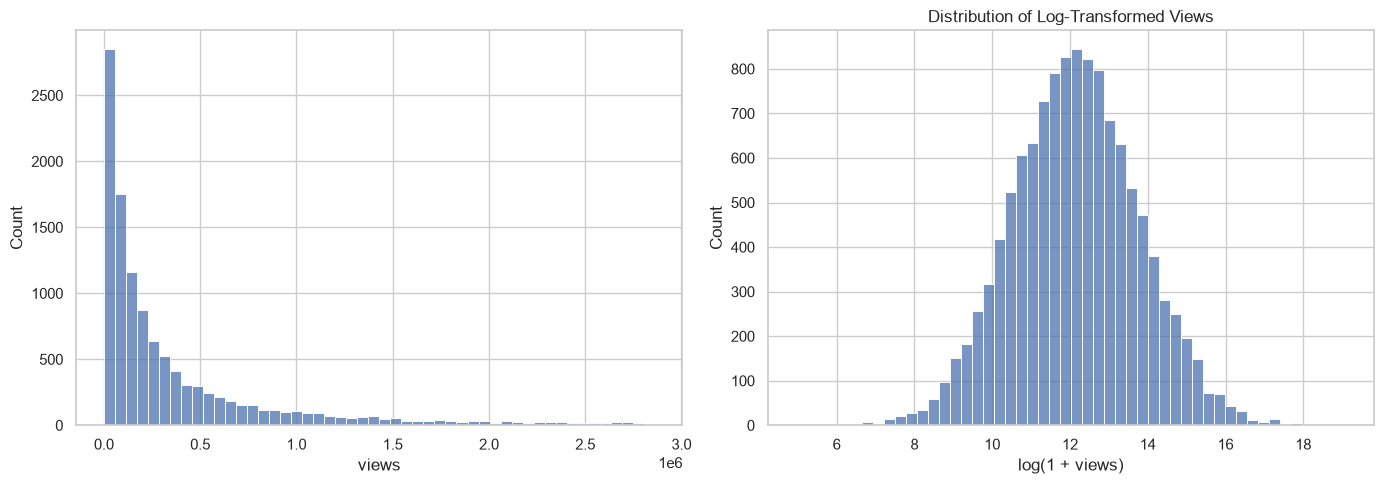

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

upper_limit = df["views"].quantile(0.95)

sns.histplot(
    df["views"],
    bins=50,
    binrange=(0, upper_limit),
    ax=axes[0]
)

sns.histplot(
    np.log1p(df["views"]),
    bins=50,
    ax=axes[1]
)
axes[1].set_title("Distribution of Log-Transformed Views")
axes[1].set_xlabel("log(1 + views)")

plt.tight_layout()
plt.show()

#### Are most videos uploaded by large/ small channels? 

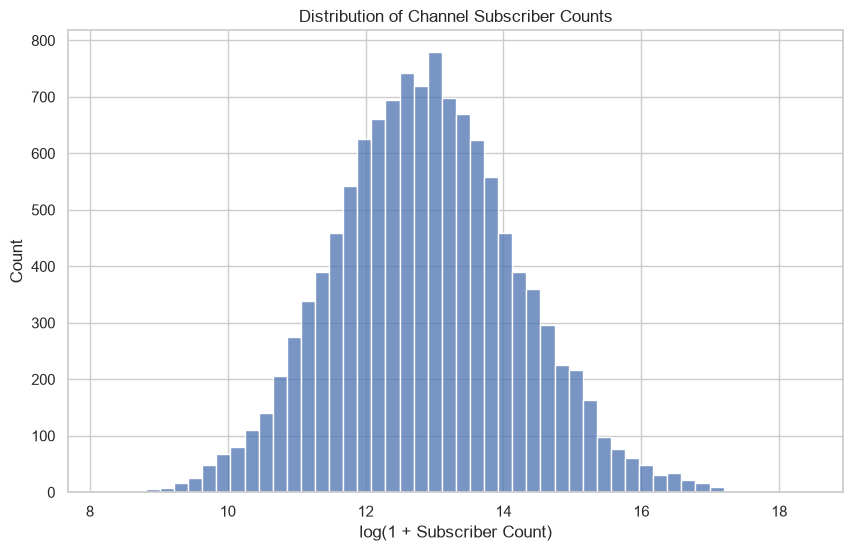

In [6]:
sns.histplot(
    np.log1p(df["subscriber_count"]),
    bins=50
)

plt.title("Distribution of Channel Subscriber Counts")
plt.xlabel("log(1 + Subscriber Count)")
plt.show()

#### Distribution of video length

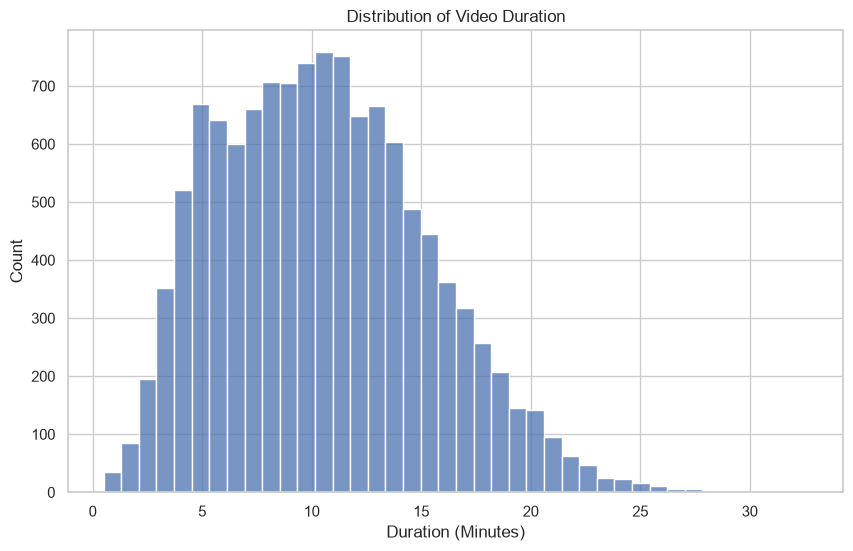

In [106]:
df["duration_min"] = df["duration_sec"] / 60

sns.histplot(df["duration_min"], bins=40)

plt.title("Distribution of Video Duration")
plt.xlabel("Duration (Minutes)")
plt.show()

#### Which content category have the highest rate? 

In [8]:
category_viral = (
    df.groupby("category")["viral"]
    .agg(["mean", "count"])
    .sort_values("mean", ascending=False)
)

category_viral["viral_rate_pct"] = category_viral["mean"] * 100

print(category_viral)

               mean  count  viral_rate_pct
category                                  
Music      0.572165    776       57.216495
Comedy     0.352258    775       35.225806
Sports     0.275434    806       27.543424
Gaming     0.242875    807       24.287485
Beauty     0.233782    817       23.378213
Tech       0.190534    824       19.053398
News       0.185455    825       18.545455
Cooking    0.171285    794       17.128463
Finance    0.152253    821       15.225335
DIY        0.134788    779       13.478819
Education  0.123037    764       12.303665
Fitness    0.114691    776       11.469072
Science    0.110149    808       11.014851
Travel     0.083024    807        8.302354
Vlog       0.071864    821        7.186358


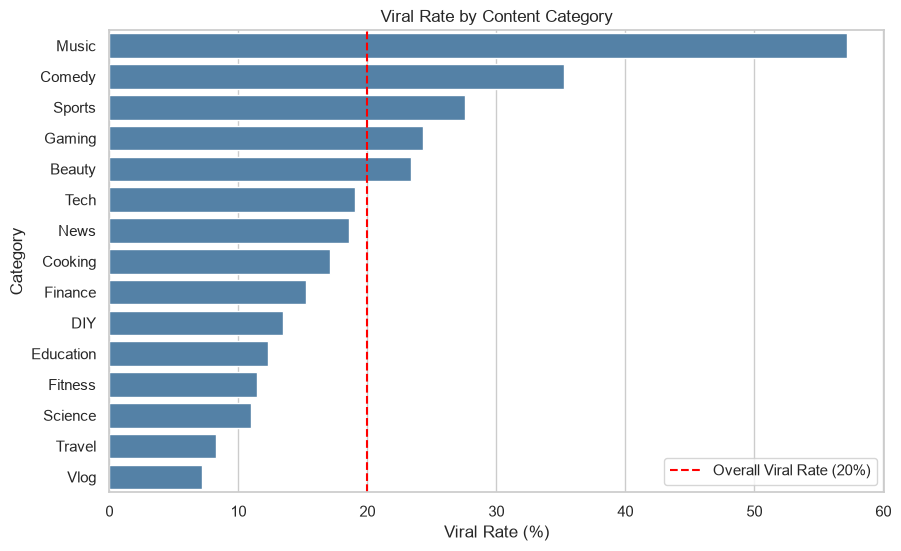

In [107]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=category_viral.reset_index(),
    x="viral_rate_pct",
    y="category",
    color="steelblue"
)

plt.axvline(
    20,
    color="red",
    linestyle="--",
    label="Overall Viral Rate (20%)"
)

plt.title("Viral Rate by Content Category")
plt.xlabel("Viral Rate (%)")
plt.ylabel("Category")
plt.legend()
plt.show()

#### Are videos from larger channels more likely to go viral? 

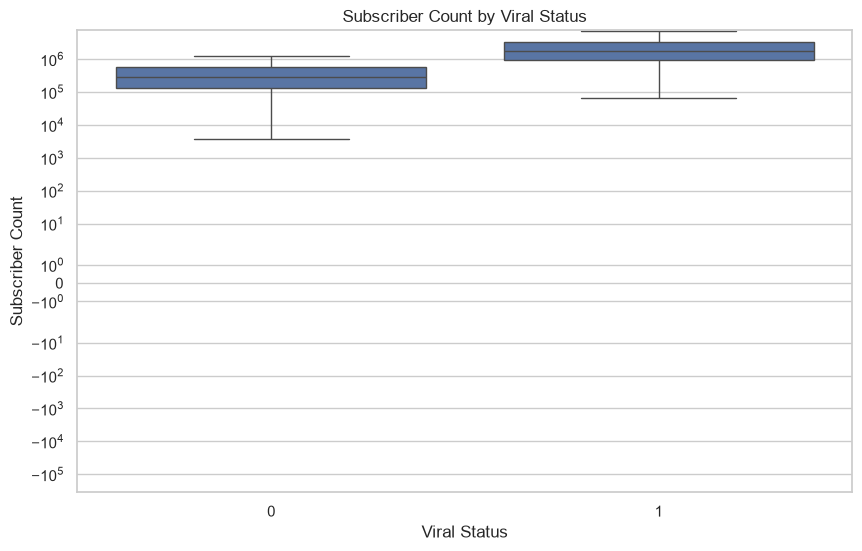

In [10]:
sns.boxplot(
    data=df,
    x="viral",
    y="subscriber_count",
    showfliers=False
)

plt.yscale("symlog")
plt.title("Subscriber Count by Viral Status")
plt.xlabel("Viral Status")
plt.ylabel("Subscriber Count")
plt.show()

In [11]:
df.groupby("viral")["subscriber_count"].median()

viral
0     279402.0
1    1763070.0
Name: subscriber_count, dtype: float64

#### Are thumbnails containing faces more likely to go viral? 

thumbnail_face
0    18.146450
1    22.777431
Name: viral, dtype: float64


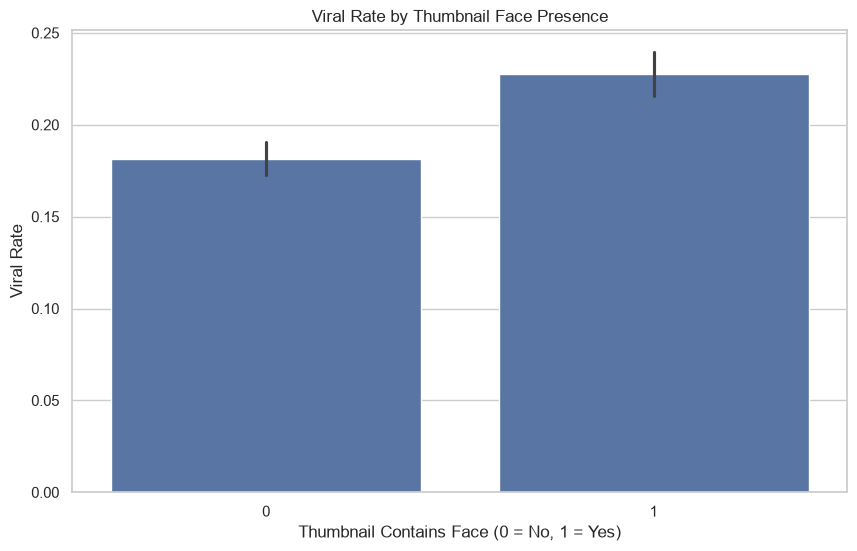

In [12]:
thumbnail_viral = (
    df.groupby("thumbnail_face")["viral"]
    .mean() * 100
)

print(thumbnail_viral)

sns.barplot(
    data=df,
    x="thumbnail_face",
    y="viral",
    errorbar=("ci", 95)
)

plt.title("Viral Rate by Thumbnail Face Presence")
plt.xlabel("Thumbnail Contains Face (0 = No, 1 = Yes)")
plt.ylabel("Viral Rate")
plt.show()

#### Does upload hour affects whether a video goes viral? 

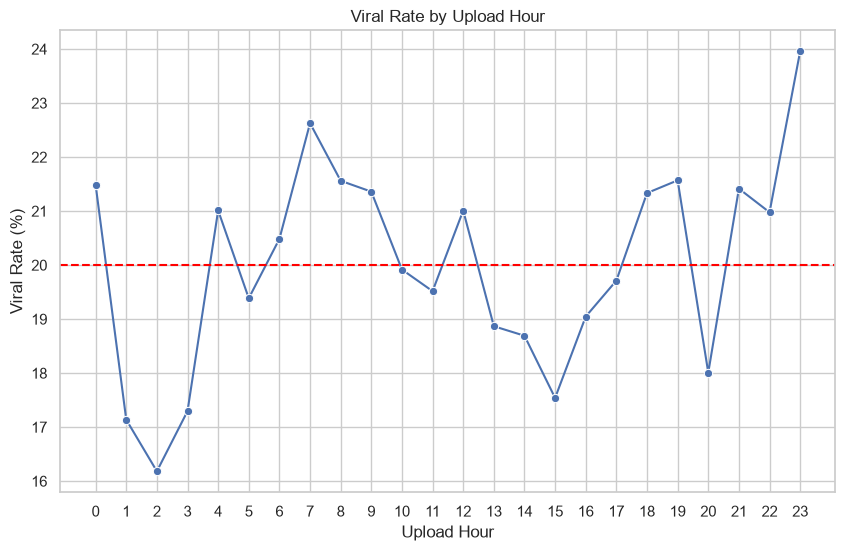

In [13]:
hourly_viral = (
    df.groupby("upload_hour")["viral"]
    .mean() * 100
)

sns.lineplot(
    x=hourly_viral.index,
    y=hourly_viral.values,
    marker="o"
)

plt.axhline(20, color="red", linestyle="--")
plt.title("Viral Rate by Upload Hour")
plt.xlabel("Upload Hour")
plt.ylabel("Viral Rate (%)")
plt.xticks(range(0, 24))
plt.show()

#### Does duration of video affects whether the video goes viral?

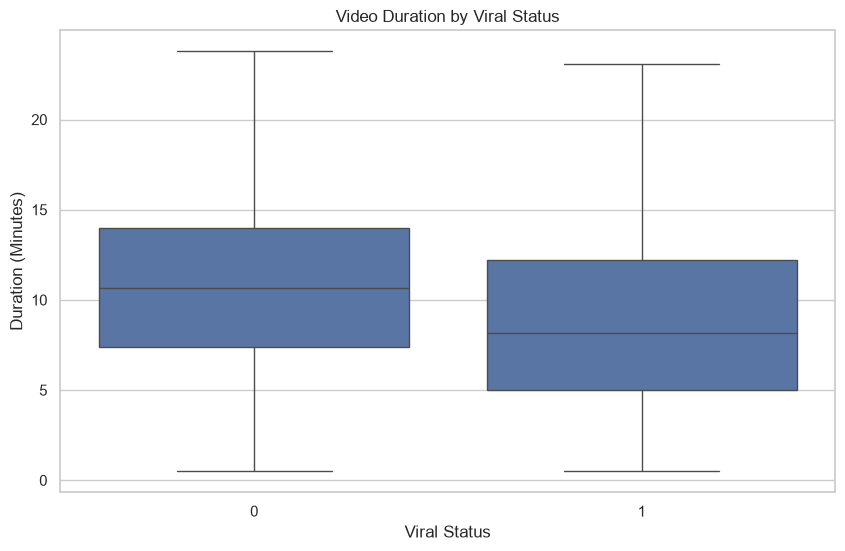

In [14]:
sns.boxplot(
    data=df,
    x="viral",
    y="duration_min",
    showfliers=False
)

plt.title("Video Duration by Viral Status")
plt.xlabel("Viral Status")
plt.ylabel("Duration (Minutes)")
plt.show()

#### Key Findings

| Research Question | Finding | Implication |
|---|---|---|
| Are views skewed? | The distribution of views is highly right-skewed, with most videos receiving relatively few views and a small number receiving exceptionally high views. | Apply a log transformation to views for regression modelling to reduce skewness. |
| Which category has the highest viral rate? | Music, Comedy, Sports, Gaming, and Beauty have the highest observed viral rates. | Content category may be an important predictor of virality and should be included in the classification model. |
| Does subscriber count matter? | Viral videos tend to have slightly different subscriber counts, but there is substantial overlap between viral and non-viral videos. | Subscriber count may have limited predictive power individually. Apply log transformation and assess its importance in multivariate models. |
| Do thumbnails with faces matter? | Videos with faces in their thumbnails have a viral rate of 27.5%, compared to 17.5% for videos without faces. | Thumbnail face presence is positively associated with virality. Conduct statistical hypothesis testing to determine whether the difference is significant. |
| Does upload timing matter? | Viral rates vary across upload hours, with identifiable peak and off-peak periods. | Upload timing may be associated with virality. Investigate statistical significance and potential interactions with content category. |
| Does video duration matter? | No clear relationship between video duration and virality was observed during EDA. | Video duration may have limited predictive power, but nonlinear relationships should be examined before excluding it from the model. |

### 2. Statistical Analysis

##### Thumbnail face presence

In [16]:
#further testing on thumbnail face presence 
from scipy.stats import chi2_contingency

contingency_table = pd.crosstab(
    df["thumbnail_face"],
    df["viral"]
)

chi2, p_value, dof, expected = chi2_contingency(
    contingency_table
)

print("Chi-square statistic:", chi2)
print("P-value:", p_value)

if p_value < 0.05:
    print("Reject H0: Significant association.")
else:
    print("Fail to reject H0: Insufficient evidence of association.")

Chi-square statistic: 38.32190906110942
P-value: 5.998538396304456e-10
Reject H0: Significant association.


In [17]:
import numpy as np

n = contingency_table.to_numpy().sum()

cramers_v = np.sqrt(
    chi2 / (n * (min(contingency_table.shape) - 1))
)

print(f"Cramér's V: {cramers_v:.4f}")

Cramér's V: 0.0565


In [18]:
print(pd.crosstab(df["thumbnail_face"], df["viral"]))

print(
    df.groupby("thumbnail_face")["viral"]
    .agg(["mean", "count"])
)

viral              0     1
thumbnail_face            
0               5891  1306
1               3709  1094
                    mean  count
thumbnail_face                 
0               0.181464   7197
1               0.227774   4803


#### Association Between Thumbnail Face Presence and Virality

**Hypothesis:**
- H₀: Thumbnail face presence and virality are independent.
- H₁: Thumbnail face presence and virality are associated.

**Statistical Test:** Chi-square Test of Independence

**Decision:** Reject H₀ at α = 0.05.

The chi-square test indicates a statistically significant association between thumbnail face presence and video virality (p < 0.001).
Videos with faces in their thumbnails have a higher observed viral rate (22.78%) than videos without faces (18.15%), representing a difference of 4.63 percentage points.
However, Cramér's V of 0.0565 indicates a very weak association.
This suggests that although thumbnail face presence is statistically associated with virality, it may have limited predictive power when considered independently.

**Conclusion:**
Thumbnail face presence should be retained as a candidate feature for classification modelling. Its contribution should be evaluated alongside other variables such as content category, subscriber count, and upload timing.
Further multivariate analysis is needed to determine whether the association persists after accounting for other video characteristics.


##### Content category

In [19]:
from scipy.stats import chi2_contingency
import numpy as np
import pandas as pd

category_table = pd.crosstab(
    df["category"],
    df["viral"]
)

chi2, p_value, dof, expected = chi2_contingency(category_table)

n = category_table.to_numpy().sum()

cramers_v = np.sqrt(
    chi2 / (n * (min(category_table.shape) - 1))
)

print(f"Chi-square statistic: {chi2:.4f}")
print(f"P-value: {p_value:.6g}")
print(f"Degrees of freedom: {dof}")
print(f"Cramér's V: {cramers_v:.4f}")
print(f"Minimum expected count: {expected.min():.2f}")

Chi-square statistic: 1123.4758
P-value: 4.84004e-231
Degrees of freedom: 14
Cramér's V: 0.3060
Minimum expected count: 152.80


#### Association Between Content Category and Virality

**Hypothesis:**
- H₀: Content category and virality are independent.
- H₁: Content category and virality are associated.

**Statistical Test:** Chi-square Test of Independence

**Decision:** Reject H₀ at α = 0.05.

The chi-square test indicates a statistically significant association between content category and video virality (p < 0.001).
Cramér's V of 0.3060 suggests a moderate association, indicating that content category is meaningfully related to viral status.
Compared to thumbnail face presence, content category demonstrates a substantially stronger association with virality.
The minimum expected frequency exceeds 5, satisfying the expected-frequency assumption of the chi-square test.

**Conclusion:**
Content category is a promising predictive feature for virality classification and should be included in subsequent machine learning models.
However, statistical association does not establish causation or guarantee predictive performance. Its contribution should be evaluated using held-out data and multivariate models.

In [20]:
#Which category contributes the most? 

# Calculate standardised Pearson residuals
residuals = (category_table - expected) / np.sqrt(expected)

# Focus on viral videos (viral = 1)
viral_residuals = residuals[1].sort_values(ascending=False)

print(viral_residuals)

category
Music        23.182023
Comedy        9.477988
Sports        4.788738
Gaming        2.723481
Beauty        2.159151
Tech         -0.607598
News         -0.934199
Cooking      -1.809296
Finance      -3.059141
DIY          -4.069865
Education    -4.756808
Fitness      -5.313885
Science      -5.711050
Travel       -7.430537
Vlog         -8.209735
Name: 1, dtype: float64


#### Upload timing

In [22]:
from scipy.stats import chi2_contingency

hour_table = pd.crosstab(
    df["upload_hour"],
    df["viral"]
)

chi2, p_value, dof, expected = chi2_contingency(hour_table)

n = hour_table.to_numpy().sum()

cramers_v = np.sqrt(
    chi2 / (n * (min(hour_table.shape) - 1))
)

print(f"Chi-square statistic: {chi2:.4f}")
print(f"P-value: {p_value:.6g}")
print(f"Degrees of freedom: {dof}")
print(f"Cramér's V: {cramers_v:.4f}")
print(f"Minimum expected count: {expected.min():.2f}")

Chi-square statistic: 25.7649
P-value: 0.312089
Degrees of freedom: 23
Cramér's V: 0.0463
Minimum expected count: 90.80


#### Association Between Upload Hour and Virality

**Hypothesis:**
- H₀: Upload hour and virality are independent.
- H₁: Upload hour and virality are associated.

**Statistical Test:** Chi-square Test of Independence

**Decision:** Do not reject H₀ at α = 0.05.

The chi-square test indicates that there is insufficient statistical evidence of an association between upload hour and video virality (p = 0.3121).
Cramér's V of 0.0463 suggests a very weak observed association.
Although exploratory data analysis revealed apparent peak and off-peak upload periods, these differences are not statistically significant at the 5% level.
The minimum expected frequency exceeds 5, satisfying the expected-frequency assumption of the chi-square test.

**Conclusion:**
Upload hour does not demonstrate a statistically significant overall association with virality in this dataset.
However, this does not prove that upload timing has no effect. Potential nonlinear relationships or interactions with content category may still exist.
Upload hour can be retained as a candidate feature during machine learning, with its predictive contribution evaluated using cross-validation and feature importance analysis.

#### Subscriber count

In [23]:
from scipy.stats import mannwhitneyu

non_viral = df.loc[
    df["viral"] == 0, "subscriber_count"
]

viral = df.loc[
    df["viral"] == 1, "subscriber_count"
]

u_stat, p_value = mannwhitneyu(
    viral,
    non_viral,
    alternative="two-sided"
)

print(f"Mann-Whitney U statistic: {u_stat:.4f}")
print(f"P-value: {p_value:.6g}")

print("\nMedian Subscriber Counts:")
print(df.groupby("viral")["subscriber_count"].median())

Mann-Whitney U statistic: 20862895.0000
P-value: 0

Median Subscriber Counts:
viral
0     279402.0
1    1763070.0
Name: subscriber_count, dtype: float64


In [24]:
n1 = len(viral)
n2 = len(non_viral)

rank_biserial = (2 * u_stat / (n1 * n2)) - 1

print(f"Rank-biserial correlation: {rank_biserial:.4f}")

Rank-biserial correlation: 0.8110


#### Association Between Subscriber Count and Virality

**Hypotheses:**
- H₀: Subscriber count distributions are identical for viral and non-viral videos.
- H₁: Subscriber count distributions differ between viral and non-viral videos.

**Statistical Test:** Mann–Whitney U Test

**Decision:** Reject H₀ at α = 0.05.

The Mann–Whitney U test indicates a statistically significant difference in subscriber count distributions between viral and non-viral videos (p < 0.001).
Viral videos have a substantially higher median subscriber count (1,763,070) than non-viral videos (279,402), approximately 6.31 times higher.
The rank-biserial correlation of 0.8110 indicates a very large rank-based difference between the two groups.

**Conclusion:**
Subscriber count is strongly associated with video virality and is a promising predictive feature for classification modelling.
A log transformation should be considered to reduce skewness, while its predictive contribution should be evaluated using multivariate models and held-out data.
The observed association does not establish a causal relationship.

#### Video Duration

In [25]:
from scipy.stats import mannwhitneyu

viral_duration = df.loc[
    df["viral"] == 1, "duration_sec"
]

non_viral_duration = df.loc[
    df["viral"] == 0, "duration_sec"
]

u_stat, p_value = mannwhitneyu(
    viral_duration,
    non_viral_duration,
    alternative="two-sided"
)

n1 = len(viral_duration)
n2 = len(non_viral_duration)

rank_biserial = (2 * u_stat / (n1 * n2)) - 1

print(f"Mann-Whitney U statistic: {u_stat:.4f}")
print(f"P-value: {p_value:.6g}")
print(f"Rank-biserial correlation: {rank_biserial:.4f}")

print("\nMedian Video Duration:")
print(df.groupby("viral")["duration_sec"].median())

Mann-Whitney U statistic: 8745010.5000
P-value: 1.17051e-74
Rank-biserial correlation: -0.2409

Median Video Duration:
viral
0    638.0
1    490.5
Name: duration_sec, dtype: float64


#### Association Between Video Duration and Virality

**Hypotheses:**
- H₀: Video duration distributions are identical for viral and non-viral videos.
- H₁: Video duration distributions differ between viral and non-viral videos.

**Statistical Test:** Mann–Whitney U Test

**Decision:** Reject H₀ at α = 0.05.

The Mann–Whitney U test indicates a statistically significant difference in video duration distributions between viral and non-viral videos (p < 0.001).
Viral videos have a median duration of 490.5 seconds, compared to 638 seconds for non-viral videos, making them approximately 23.1% shorter in terms of median duration.
The rank-biserial correlation of -0.2409 indicates a negative, small-to-moderate rank-based association.
This suggests that shorter videos tend to be associated with higher virality in this dataset.

**Conclusion:**
Video duration is a potentially useful predictor of virality and should be retained for machine learning.
Further analysis should investigate nonlinear relationships and whether the association persists after controlling for content category and subscriber count.
The observed relationship does not establish that shortening a video causes an increase in virality.

### 3. Feature engineering

In [108]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import (
    OneHotEncoder,
    StandardScaler,
    FunctionTransformer
)
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer


In [109]:
#exclude views, likes, comments, and shares from the input features as they are post-publication outcomes
#and using them would introduce information leakage into a pre-upload prediction model.
features = [
    "category",
    "duration_sec",
    "title_length",
    "thumbnail_face",
    "upload_hour",
    "upload_day",
    "tags_count",
    "description_length",
    "subscriber_count"
]

target = "viral"

X = df[features].copy()
y = df[target].copy()

print("Features:", X.shape)
print("Target:", y.shape)

display(X.head())

Features: (12000, 9)
Target: (12000,)


,category,duration_sec,title_length,thumbnail_face,upload_hour,upload_day,tags_count,description_length,subscriber_count
0,Beauty,517,64,1,23,Wed,27,429,907474
1,Tech,495,47,1,23,Mon,10,222,1004641
2,Beauty,311,76,0,17,Mon,13,520,168170
3,Fitness,590,69,0,0,Mon,17,309,285593
4,Tech,380,58,1,19,Mon,0,101,1073326


In [28]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training shape:", X_train.shape)
print("Testing shape:", X_test.shape)

print("\nTraining viral rate:")
print(y_train.value_counts(normalize=True))

print("\nTesting viral rate:")
print(y_test.value_counts(normalize=True))

Training shape: (9600, 9)
Testing shape: (2400, 9)

Training viral rate:
viral
0    0.8
1    0.2
Name: proportion, dtype: float64

Testing viral rate:
viral
0    0.8
1    0.2
Name: proportion, dtype: float64


In [29]:
X_train["subscriber_log"] = np.log1p(
    X_train["subscriber_count"]
)

X_test["subscriber_log"] = np.log1p(
    X_test["subscriber_count"]
)

In [30]:
X_train["duration_min"] = (
    X_train["duration_sec"] / 60
)

X_test["duration_min"] = (
    X_test["duration_sec"] / 60
)

In [31]:
for dataset in [X_train, X_test]:
    dataset["hour_sin"] = np.sin(
        2 * np.pi * dataset["upload_hour"] / 24
    )

    dataset["hour_cos"] = np.cos(
        2 * np.pi * dataset["upload_hour"] / 24
    )

In [32]:
X_train = X_train.drop(
    columns=["subscriber_count", "duration_sec", "upload_hour"]
)

X_test = X_test.drop(
    columns=["subscriber_count", "duration_sec", "upload_hour"]
)

print("Final training features:")
print(X_train.columns.tolist())

display(X_train.head())

Final training features:
['category', 'title_length', 'thumbnail_face', 'upload_day', 'tags_count', 'description_length', 'subscriber_log', 'duration_min', 'hour_sin', 'hour_cos']


,category,title_length,thumbnail_face,upload_day,tags_count,description_length,subscriber_log,duration_min,hour_sin,hour_cos
7262,Education,72,0,Sat,15,569,14.841389,20.016667,-0.258819,-0.965926
3934,Science,55,0,Mon,12,368,12.925341,15.216667,0.965926,0.258819
3527,DIY,58,0,Mon,20,528,14.093419,19.233333,0.707107,-0.707107
9561,Tech,65,0,Thu,7,695,12.844890,12.416667,0.965926,0.258819
9930,Music,58,1,Tue,25,201,14.792543,1.533333,-0.707107,0.707107


In [33]:
#preprocessing pipeline 
categorical_features = [
    "category",
    "upload_day"
]

numerical_features = [
    "title_length",
    "tags_count",
    "description_length",
    "subscriber_log",
    "duration_min",
    "hour_sin",
    "hour_cos"
]

binary_features = [
    "thumbnail_face"
]

numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(
        handle_unknown="ignore"
    ))
])

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numerical_features),
        ("cat", categorical_transformer, categorical_features),
        ("binary", "passthrough", binary_features)
    ]
)

In [34]:
X_train_processed = preprocessor.fit_transform(
    X_train
)

X_test_processed = preprocessor.transform(
    X_test
)

print("Processed training shape:", X_train_processed.shape)
print("Processed testing shape:", X_test_processed.shape)

Processed training shape: (9600, 30)
Processed testing shape: (2400, 30)


In [35]:
feature_names = preprocessor.get_feature_names_out()

print("Total transformed features:", len(feature_names))

print(feature_names)

Total transformed features: 30
['num__title_length' 'num__tags_count' 'num__description_length'
 'num__subscriber_log' 'num__duration_min' 'num__hour_sin' 'num__hour_cos'
 'cat__category_Beauty' 'cat__category_Comedy' 'cat__category_Cooking'
 'cat__category_DIY' 'cat__category_Education' 'cat__category_Finance'
 'cat__category_Fitness' 'cat__category_Gaming' 'cat__category_Music'
 'cat__category_News' 'cat__category_Science' 'cat__category_Sports'
 'cat__category_Tech' 'cat__category_Travel' 'cat__category_Vlog'
 'cat__upload_day_Fri' 'cat__upload_day_Mon' 'cat__upload_day_Sat'
 'cat__upload_day_Sun' 'cat__upload_day_Thu' 'cat__upload_day_Tue'
 'cat__upload_day_Wed' 'binary__thumbnail_face']


In [ ]:
import joblib
from pathlib import Path

Path("../models").mkdir(exist_ok=True)

joblib.dump(
    preprocessor,
    "../models/preprocessor.joblib"
)

Preprocessor saved successfully.


#### Feature Engineering and Data Preprocessing
Prepare the dataset for machine learning while preventing data leakage and improving feature representation.

##### Feature Selection
Selected nine pre-upload video characteristics as predictors.
Excluded `views`, `likes`, `comments`, and `shares` because these variables are only available after publication and would introduce information leakage into a pre-upload prediction model.

##### Feature Engineering
- Applied log transformation to subscriber count to reduce skewness.
- Converted video duration from seconds to minutes.
- Applied sine and cosine transformations to upload hour to capture cyclical relationships.
- Retained thumbnail face presence as a binary feature.

##### Data Splitting
- Training set: 80% (9,600 observations)
- Testing set: 20% (2,400 observations)
- Used stratified sampling to preserve the 20% viral rate.

##### Data Preprocessing
- StandardScaler for numerical features.
- OneHotEncoder for categorical features.
- Median imputation for numerical missing values.
- Most-frequent imputation for categorical missing values.
- ColumnTransformer to combine preprocessing steps.

##### Data Leakage Prevention
Preprocessing parameters were fitted using training data only and subsequently applied to testing data.

### 4. Classification Modelling 

In [38]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.pipeline import Pipeline
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_auc_score,
    average_precision_score,
    RocCurveDisplay,
    PrecisionRecallDisplay
)

from xgboost import XGBClassifier

In [39]:
models = {
    "Dummy": DummyClassifier(
        strategy="prior"
    ),

    "Logistic Regression": LogisticRegression(
        max_iter=2000,
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        random_state=42,
        n_jobs=-1
    ),

    "XGBoost": XGBClassifier(
        n_estimators=200,
        max_depth=4,
        learning_rate=0.05,
        eval_metric="logloss",
        random_state=42,
        n_jobs=1
    )
}

In [40]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

scoring = {
    "accuracy": "accuracy",
    "precision": "precision",
    "recall": "recall",
    "f1": "f1",
    "roc_auc": "roc_auc",
    "average_precision": "average_precision"
}

In [41]:
from sklearn.base import clone

results = []

for name, model in models.items():

    pipeline = Pipeline([
        ("preprocessor", clone(preprocessor)),
        ("classifier", model)
    ])

    scores = cross_validate(
        pipeline,
        X_train,
        y_train,
        cv=cv,
        scoring=scoring,
        n_jobs=-1
    )

    results.append({
        "Model": name,
        "Accuracy": scores["test_accuracy"].mean(),
        "Precision": scores["test_precision"].mean(),
        "Recall": scores["test_recall"].mean(),
        "F1": scores["test_f1"].mean(),
        "ROC-AUC": scores["test_roc_auc"].mean(),
        "PR-AUC": scores["test_average_precision"].mean()
    })

results_df = pd.DataFrame(results)

display(
    results_df.sort_values(
        "PR-AUC",
        ascending=False
    ).round(4)
)

/Users/wanyu/Desktop/Kaggle/.venv/lib/python3.14/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Users/wanyu/Desktop/Kaggle/.venv/lib/python3.14/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Users/wanyu/Desktop/Kaggle/.venv/lib/python3.14/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.sh

,Model,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC
1,Logistic Regression,0.8710,0.7332,0.5609,0.6349,0.9059,0.7379
3,XGBoost,0.8692,0.7379,0.5365,0.6211,0.9026,0.7296
2,Random Forest,0.8673,0.7324,0.5318,0.6157,0.8905,0.7073
0,Dummy,0.8000,0.0000,0.0000,0.0000,0.5000,0.2000


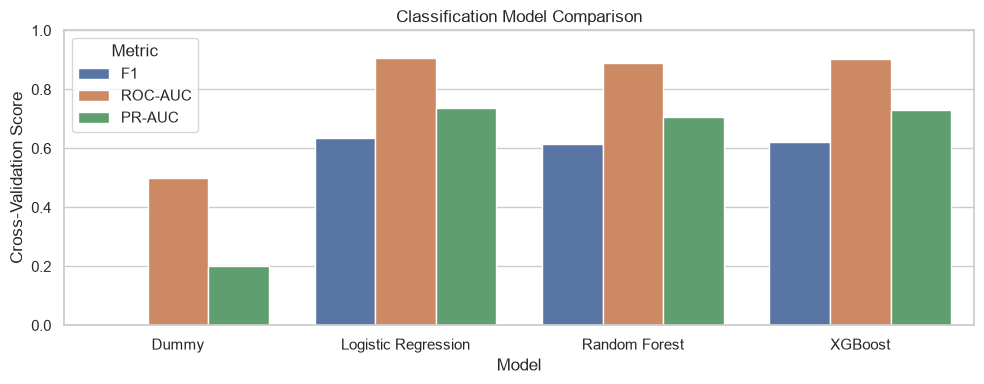

In [42]:
plot_df = results_df.melt(
    id_vars="Model",
    value_vars=["F1", "ROC-AUC", "PR-AUC"],
    var_name="Metric",
    value_name="Score"
)

plt.figure(figsize=(10, 4))

sns.barplot(
    data=plot_df,
    x="Model",
    y="Score",
    hue="Metric"
)

plt.title("Classification Model Comparison")
plt.ylabel("Cross-Validation Score")
plt.ylim(0, 1)
plt.tight_layout()
plt.show()

Logistic Regression is currently the strongest candidate for virality classification based on cross-validation performance.
However, further analysis is required to determine whether its advantage is consistent across validation folds.
The model's relatively low recall also suggests that classification threshold optimisation may improve its ability to identify viral videos.

In [43]:
#tune logistic regression 
lr_pipeline = Pipeline([
    ("preprocessor", clone(preprocessor)),
    ("classifier", LogisticRegression(
        max_iter=3000,
        random_state=42
    ))
])

In [44]:
lr_param_dist = {
    "classifier__C": np.logspace(-3, 2, 30),
    "classifier__class_weight": [None, "balanced"]
}

In [45]:
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

lr_search = RandomizedSearchCV(
    estimator=lr_pipeline,
    param_distributions=lr_param_dist,
    n_iter=20,
    scoring="average_precision",
    cv=cv,
    random_state=42,
    n_jobs=-1,
    verbose=1,
    refit=True
)

lr_search.fit(X_train, y_train)

print("Best Logistic Regression Parameters:")
print(lr_search.best_params_)

print("\nBest Cross-Validation PR-AUC:")
print(round(lr_search.best_score_, 4))

Fitting 5 folds for each of 20 candidates, totalling 100 fits
Best Logistic Regression Parameters:
{'classifier__class_weight': 'balanced', 'classifier__C': np.float64(0.010826367338740546)}

Best Cross-Validation PR-AUC:
0.7392


In [46]:
lr_results = pd.DataFrame(lr_search.cv_results_)

display(
    lr_results[
        [
            "param_classifier__C",
            "param_classifier__class_weight",
            "mean_test_score",
            "std_test_score",
            "rank_test_score"
        ]
    ]
    .sort_values("rank_test_score")
    .head(10)
)

,param_classifier__C,param_classifier__class_weight,mean_test_score,std_test_score,rank_test_score
4,0.010826,balanced,0.739218,0.022231,1
8,0.010826,NaN,0.739124,0.021996,2
15,0.023950,balanced,0.738812,0.022032,3
16,0.004894,NaN,0.738194,0.022095,4
2,1.268961,NaN,0.737901,0.021603,5
14,30.391954,NaN,0.737862,0.021628,6
11,20.433597,NaN,0.737860,0.021626,7
7,13.738238,NaN,0.737859,0.021633,8
10,9.236709,NaN,0.737857,0.021639,9
5,45.203537,NaN,0.737852,0.021643,10


In [47]:
#tune XGBoost 
xgb_pipeline = Pipeline([
    ("preprocessor", clone(preprocessor)),
    ("classifier", XGBClassifier(
        objective="binary:logistic",
        eval_metric="logloss",
        tree_method="hist",
        random_state=42,
        n_jobs=1
    ))
])

In [48]:
xgb_param_dist = {
    "classifier__n_estimators": [100, 200, 300, 500],
    "classifier__max_depth": [2, 3, 4, 5, 6],
    "classifier__learning_rate": [0.01, 0.03, 0.05, 0.1],
    "classifier__subsample": [0.7, 0.8, 1.0],
    "classifier__colsample_bytree": [0.7, 0.8, 1.0],
    "classifier__min_child_weight": [1, 3, 5, 10],
    "classifier__reg_lambda": [0.1, 1, 5, 10]
}

In [49]:
xgb_search = RandomizedSearchCV(
    estimator=xgb_pipeline,
    param_distributions=xgb_param_dist,
    n_iter=30,
    scoring="average_precision",
    cv=cv,
    random_state=42,
    n_jobs=-1,
    verbose=1,
    refit=True
)

xgb_search.fit(X_train, y_train)

print("Best XGBoost Parameters:")
print(xgb_search.best_params_)

print("\nBest Cross-Validation PR-AUC:")
print(round(xgb_search.best_score_, 4))

Fitting 5 folds for each of 30 candidates, totalling 150 fits
Best XGBoost Parameters:
{'classifier__subsample': 1.0, 'classifier__reg_lambda': 0.1, 'classifier__n_estimators': 300, 'classifier__min_child_weight': 1, 'classifier__max_depth': 2, 'classifier__learning_rate': 0.03, 'classifier__colsample_bytree': 1.0}

Best Cross-Validation PR-AUC:
0.7383


In [50]:
xgb_results = pd.DataFrame(xgb_search.cv_results_)

display(
    xgb_results[
        [
            "param_classifier__n_estimators",
            "param_classifier__max_depth",
            "param_classifier__learning_rate",
            "param_classifier__subsample",
            "mean_test_score",
            "std_test_score",
            "rank_test_score"
        ]
    ]
    .sort_values("rank_test_score")
    .head(10)
)

,param_classifier__n_estimators,param_classifier__max_depth,param_classifier__learning_rate,param_classifier__subsample,mean_test_score,std_test_score,rank_test_score
26,300,2,0.03,1.0,0.738276,0.021230,1
29,300,2,0.01,0.8,0.737000,0.022950,2
21,300,3,0.03,1.0,0.735665,0.021151,3
19,100,3,0.03,1.0,0.735325,0.022181,4
15,200,2,0.10,1.0,0.734580,0.020541,5
3,100,4,0.03,0.8,0.733918,0.020863,6
22,500,5,0.01,0.8,0.731962,0.021299,7
12,200,5,0.01,0.7,0.731749,0.022723,8
7,300,4,0.01,0.8,0.731510,0.021005,9
18,300,4,0.03,0.8,0.731344,0.022290,10


In [51]:
tuning_comparison = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "XGBoost"
    ],
    "Baseline PR-AUC": [
        0.7379,
        0.7296
    ],
    "Tuned PR-AUC": [
        lr_search.best_score_,
        xgb_search.best_score_
    ]
})

tuning_comparison["Improvement"] = (
    tuning_comparison["Tuned PR-AUC"]
    - tuning_comparison["Baseline PR-AUC"]
)

display(tuning_comparison.round(4))

,Model,Baseline PR-AUC,Tuned PR-AUC,Improvement
0,Logistic Regression,0.7379,0.7392,0.0013
1,XGBoost,0.7296,0.7383,0.0087


In [52]:
if lr_search.best_score_ >= xgb_search.best_score_:
    best_search = lr_search
    best_model_name = "Logistic Regression"
else:
    best_search = xgb_search
    best_model_name = "XGBoost"

best_pipeline = best_search.best_estimator_

print("Selected model:", best_model_name)
print("Best CV PR-AUC:", round(best_search.best_score_, 4))

Selected model: Logistic Regression
Best CV PR-AUC: 0.7392


#### Hyperparameter Tuning Results

**Selected Model:** Logistic Regression

**Evaluation Metric:** Average Precision (PR-AUC)

| Model Version | CV PR-AUC |
|---|---:|
| Baseline Logistic Regression | 0.7379 |
| Tuned Logistic Regression | 0.7392 |
| Improvement | +0.0013 |

**Interpretation:**
Hyperparameter tuning resulted in a marginal improvement in Logistic Regression's cross-validation PR-AUC, increasing from 0.7379 to 0.7392. The improvement of approximately 0.18% suggests that the baseline model was already performing close to the best configuration identified by the hyperparameter search.
Logistic Regression remains the selected model based on cross-validation performance.

**Conclusion:**
The tuned Logistic Regression model will be used for subsequent classification threshold optimisation and final test-set evaluation.
However, the small performance improvement should not be interpreted as conclusive evidence of better generalisation.

In [53]:
from sklearn.model_selection import cross_val_predict
from sklearn.base import clone
import numpy as np

oof_prob = cross_val_predict(
    clone(best_pipeline),
    X_train,
    y_train,
    cv=cv,
    method="predict_proba",
    n_jobs=-1
)[:, 1]

print("OOF predictions:", len(oof_prob))

OOF predictions: 9600


In [54]:
#evaluate different threshold 
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score
)

thresholds = np.arange(0.1, 0.91, 0.01)

threshold_results = []

for threshold in thresholds:
    y_pred = (oof_prob >= threshold).astype(int)

    threshold_results.append({
        "Threshold": threshold,
        "Precision": precision_score(
            y_train, y_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_train, y_pred, zero_division=0
        ),
        "F1": f1_score(
            y_train, y_pred, zero_division=0
        )
    })

threshold_df = pd.DataFrame(threshold_results)

display(threshold_df.head())

,Threshold,Precision,Recall,F1
0,0.10,0.273311,0.996875,0.429004
1,0.11,0.280152,0.996875,0.437386
2,0.12,0.286121,0.994271,0.444367
3,0.13,0.292383,0.991667,0.451613
4,0.14,0.298491,0.989062,0.458585


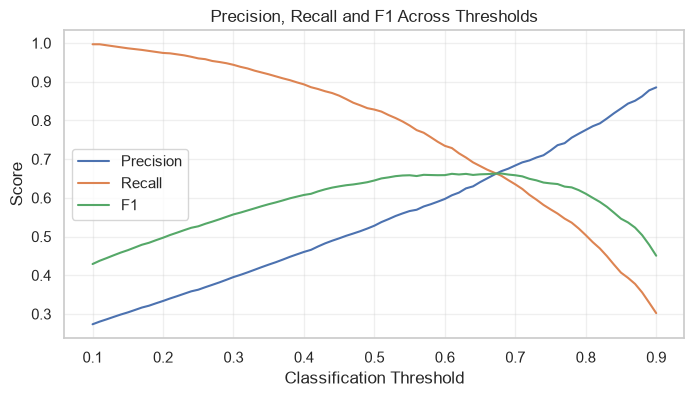

In [55]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 4))

plt.plot(
    threshold_df["Threshold"],
    threshold_df["Precision"],
    label="Precision"
)

plt.plot(
    threshold_df["Threshold"],
    threshold_df["Recall"],
    label="Recall"
)

plt.plot(
    threshold_df["Threshold"],
    threshold_df["F1"],
    label="F1"
)

plt.xlabel("Classification Threshold")
plt.ylabel("Score")
plt.title("Precision, Recall and F1 Across Thresholds")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [56]:
best_idx = threshold_df["F1"].idxmax()

best_threshold = threshold_df.loc[
    best_idx, "Threshold"
]

print(f"Best threshold: {best_threshold:.2f}")

display(threshold_df.loc[[best_idx]])

Best threshold: 0.68


,Threshold,Precision,Recall,F1
58,0.68,0.668786,0.657292,0.662989


In [57]:
from sklearn.metrics import precision_score, recall_score, f1_score
import pandas as pd

comparison_results = []

for threshold in [0.5, 0.68]:
    predictions = (oof_prob >= threshold).astype(int)

    comparison_results.append({
        "Threshold": threshold,
        "Precision": precision_score(y_train, predictions),
        "Recall": recall_score(y_train, predictions),
        "F1": f1_score(y_train, predictions)
    })

comparison_df = pd.DataFrame(comparison_results)

display(comparison_df.round(4))

,Threshold,Precision,Recall,F1
0,0.50,0.5281,0.8281,0.6449
1,0.68,0.6688,0.6573,0.6630



#### Threshold Optimisation Results

| Metric | Default (0.50) | Optimised (0.68) | Change |
|---|---:|---:|---:|
| Precision | 0.5281 | 0.6688 | +0.1407 |
| Recall | 0.8281 | 0.6573 | -0.1708 |
| F1-score | 0.6449 | 0.6630 | +0.0181 |

**Interpretation:**
Increasing the classification threshold from 0.50 to 0.68 improved precision from 52.81% to 66.88%, while recall decreased from 82.81% to 65.73%.

The F1-score increased from 0.6449 to 0.6630, indicating an improved balance between precision and recall.

**Conclusion:**
A classification threshold of 0.68 was selected because it achieved the highest F1-score among the evaluated thresholds.
This threshold will be used for final evaluation on the held-out test set.


In [58]:
#generate test predictions
import numpy as np
import pandas as pd

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    classification_report,
    ConfusionMatrixDisplay,
    RocCurveDisplay,
    PrecisionRecallDisplay
)

import matplotlib.pyplot as plt

final_threshold = 0.68

y_test_prob = best_pipeline.predict_proba(X_test)[:, 1]

y_test_pred = (
    y_test_prob >= final_threshold
).astype(int)

In [59]:
final_results = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1",
        "ROC-AUC",
        "PR-AUC"
    ],
    "Score": [
        accuracy_score(y_test, y_test_pred),
        precision_score(y_test, y_test_pred),
        recall_score(y_test, y_test_pred),
        f1_score(y_test, y_test_pred),
        roc_auc_score(y_test, y_test_prob),
        average_precision_score(y_test, y_test_prob)
    ]
})

display(final_results.round(4))

,Metric,Score
0,Accuracy,0.8571
1,Precision,0.6330
2,Recall,0.6792
3,F1,0.6553
4,ROC-AUC,0.9041
5,PR-AUC,0.7298


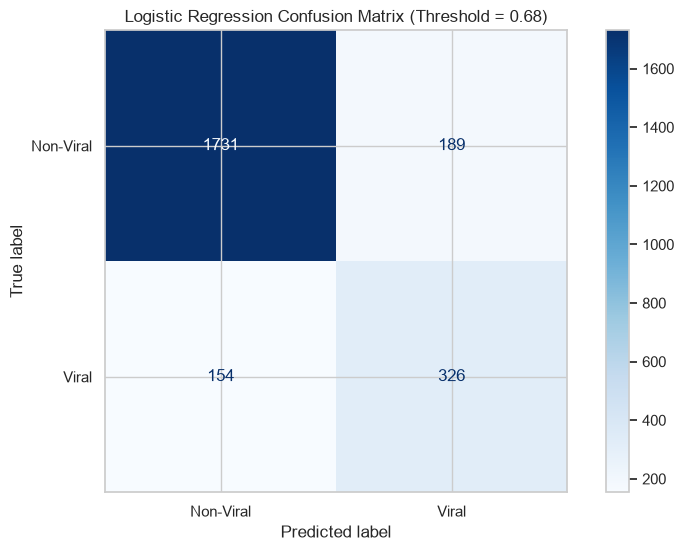

In [60]:
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_test_pred,
    display_labels=["Non-Viral", "Viral"],
    cmap="Blues"
)

plt.title(
    "Logistic Regression Confusion Matrix (Threshold = 0.68)"
)
plt.show()

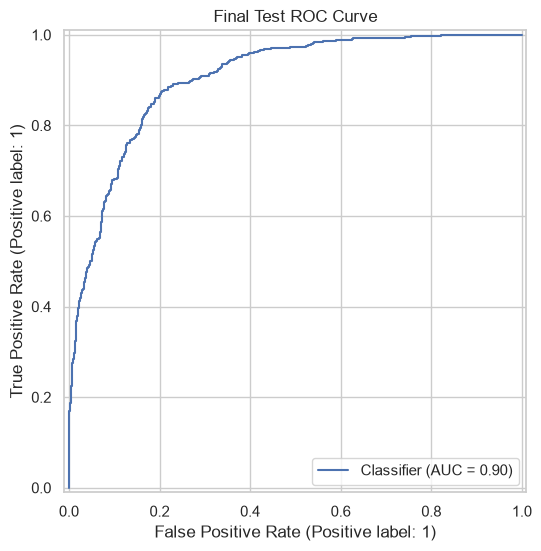

In [61]:
RocCurveDisplay.from_predictions(
    y_test,
    y_test_prob
)

plt.title("Final Test ROC Curve")
plt.show()

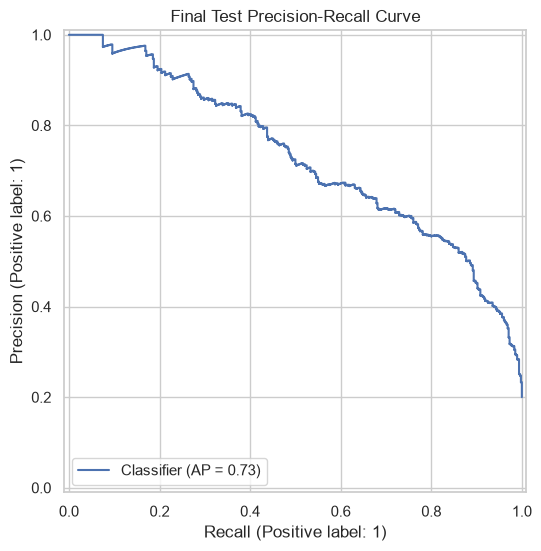

In [62]:
PrecisionRecallDisplay.from_predictions(
    y_test,
    y_test_prob
)

plt.title("Final Test Precision-Recall Curve")
plt.show()

In [63]:
test_comparison = []

for threshold in [0.50, 0.68]:
    pred = (y_test_prob >= threshold).astype(int)

    test_comparison.append({
        "Threshold": threshold,
        "Precision": precision_score(y_test, pred),
        "Recall": recall_score(y_test, pred),
        "F1": f1_score(y_test, pred)
    })

display(pd.DataFrame(test_comparison).round(4))

,Threshold,Precision,Recall,F1
0,0.50,0.5302,0.8583,0.6555
1,0.68,0.6330,0.6792,0.6553



#### Final Test Evaluation

#### Objective
Evaluate the generalisation performance of the tuned Logistic Regression model on the held-out test dataset.

#### Model Configuration
- Model: Logistic Regression
- Classification threshold: 0.68
- Test set size: 2,400 observations
- Positive class prevalence: 20%

#### Final Test Performance

| Metric | Score |
|---|---:|
| Accuracy | 0.8571 |
| Precision | 0.6330 |
| Recall | 0.6792 |
| F1-score | 0.6553 |
| ROC-AUC | 0.9041 |
| PR-AUC | 0.7298 |

#### Confusion Matrix

| Actual / Predicted | Non-Viral | Viral |
|---|---:|---:|
| Non-Viral | 1731 | 189 |
| Viral | 154 | 326 |

#### Key Findings

1. The model achieved an accuracy of 85.71%, outperforming the majority-class baseline of 80%.

2. The ROC-AUC of 0.9041 indicates strong discrimination between viral and non-viral videos.

3. The PR-AUC of 0.7298 is substantially higher than the baseline positive-class prevalence of 0.20.

4. The model correctly identified 326 of 480 viral videos, achieving a recall of 67.92%.

5. The model produced 189 false positives and 154 false negatives.

6. The test PR-AUC (0.7298) was close to the cross-validation PR-AUC (0.7392), suggesting relatively stable predictive performance.

#### Threshold Comparison

| Threshold | Precision | Recall | F1 |
|---|---:|---:|---:|
| 0.50 | 0.5302 | 0.8583 | 0.6555 |
| 0.68 | 0.6330 | 0.6792 | 0.6553 |

The optimised threshold improved precision but reduced recall.

Although the default threshold achieved a marginally higher test F1-score, the difference was negligible.

The threshold of 0.68 was retained because it was selected using training data, avoiding test-set-based threshold selection.

#### Conclusion

The tuned Logistic Regression model demonstrates strong discrimination and reasonable generalisation performance for predicting video virality.

However, its recall of 67.92% indicates that approximately 32% of viral videos remain undetected.

Further analysis should focus on model interpretability, feature importance, and identifying the characteristics of misclassified videos.

The findings are based on a synthetic dataset and may not generalise to real YouTube performance.


### 5. Model Interpretability & Feature Importance

In [64]:
#logistic regression 

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Extract fitted model
model = best_pipeline.named_steps["classifier"]

# Extract fitted preprocessor
fitted_preprocessor = best_pipeline.named_steps["preprocessor"]

# Get transformed feature names
feature_names = fitted_preprocessor.get_feature_names_out()

# Get coefficients
coefficients = model.coef_[0]

coef_df = pd.DataFrame({
    "Feature": feature_names,
    "Coefficient": coefficients,
    "Odds_Ratio": np.exp(coefficients)
})

coef_df = coef_df.sort_values(
    "Coefficient",
    ascending=False
)

display(coef_df)

,Feature,Coefficient,Odds_Ratio
3,num__subscriber_log,2.067700,7.906616
29,binary__thumbnail_face,0.309959,1.363370
8,cat__category_Comedy,0.115116,1.122003
15,cat__category_Music,0.095961,1.100716
14,cat__category_Gaming,0.079809,1.083080
1,num__tags_count,0.070047,1.072559
23,cat__upload_day_Mon,0.054031,1.055517
18,cat__category_Sports,0.040136,1.040953
28,cat__upload_day_Wed,0.020683,1.020898
9,cat__category_Cooking,0.019834,1.020032


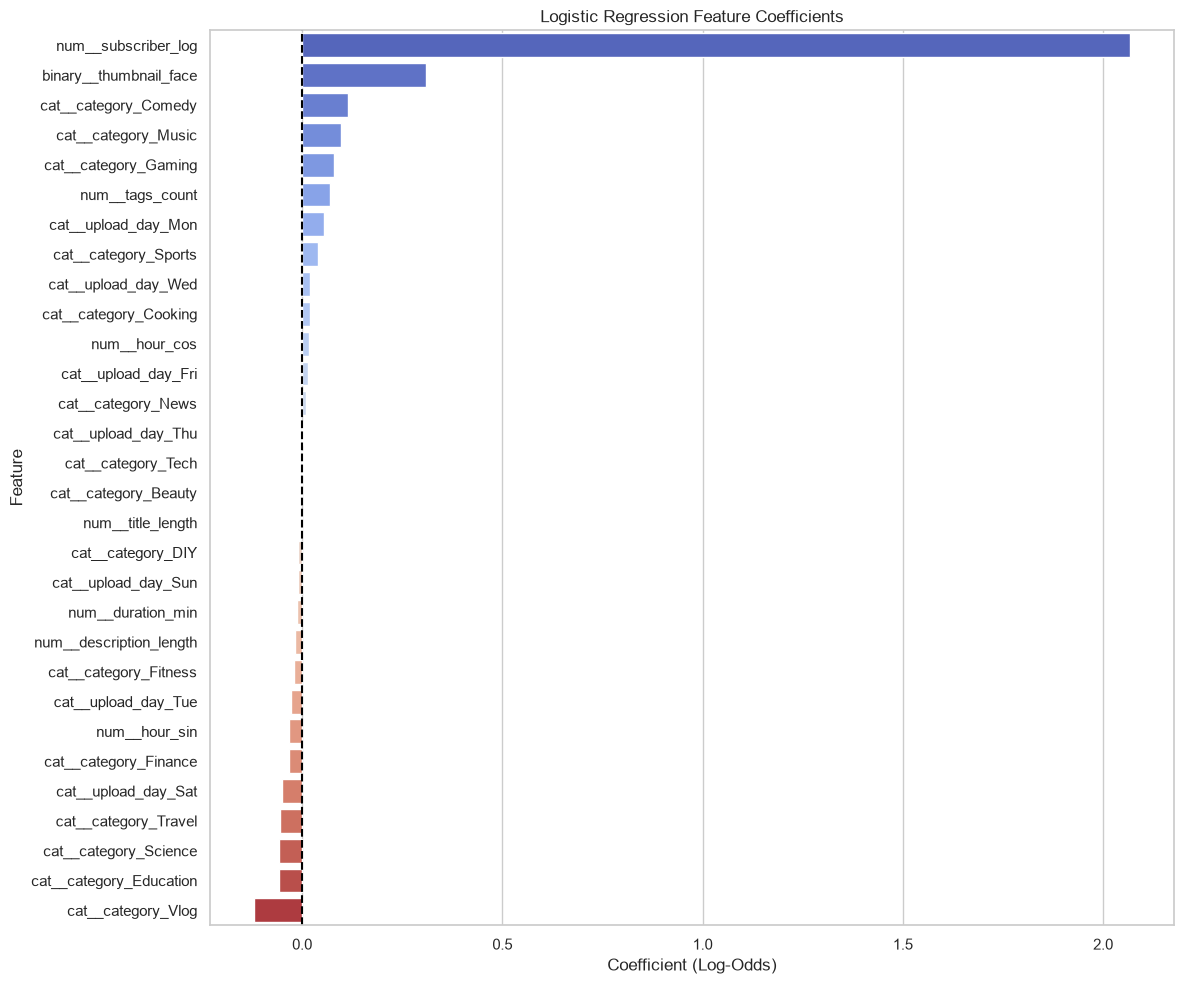

In [65]:
plt.figure(figsize=(12, 10))

sns.barplot(
    data=coef_df,
    x="Coefficient",
    y="Feature",
    hue="Feature",
    palette="coolwarm",
    legend=False
)

plt.axvline(
    x=0,
    color="black",
    linestyle="--"
)

plt.title("Logistic Regression Feature Coefficients")
plt.xlabel("Coefficient (Log-Odds)")
plt.ylabel("Feature")

plt.tight_layout()
plt.show()

In [66]:
top_positive = coef_df.nlargest(
    5, "Coefficient"
)

display(top_positive)

,Feature,Coefficient,Odds_Ratio
3,num__subscriber_log,2.067700,7.906616
29,binary__thumbnail_face,0.309959,1.363370
8,cat__category_Comedy,0.115116,1.122003
15,cat__category_Music,0.095961,1.100716
14,cat__category_Gaming,0.079809,1.083080


In [67]:
top_negative = coef_df.nsmallest(
    5, "Coefficient"
)

display(top_negative)

,Feature,Coefficient,Odds_Ratio
21,cat__category_Vlog,-0.119730,0.887160
11,cat__category_Education,-0.058600,0.943084
17,cat__category_Science,-0.056988,0.944606
20,cat__category_Travel,-0.054220,0.947224
24,cat__upload_day_Sat,-0.051084,0.950199


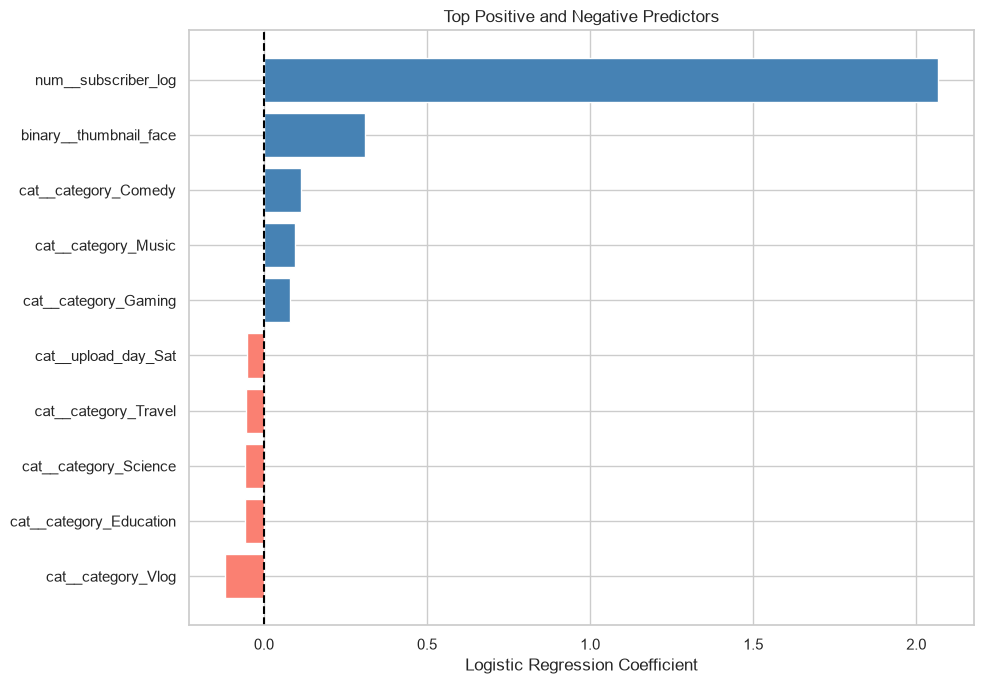

In [68]:
top_features = pd.concat([
    top_positive,
    top_negative
]).sort_values("Coefficient")

plt.figure(figsize=(10, 7))

colors = [
    "steelblue" if x > 0 else "salmon"
    for x in top_features["Coefficient"]
]

plt.barh(
    top_features["Feature"],
    top_features["Coefficient"],
    color=colors
)

plt.axvline(0, color="black", linestyle="--")

plt.title("Top Positive and Negative Predictors")
plt.xlabel("Logistic Regression Coefficient")

plt.tight_layout()
plt.show()

In [69]:
odds_df = coef_df[
    ["Feature", "Coefficient", "Odds_Ratio"]
].copy()

odds_df["Odds_Change_Pct"] = (
    odds_df["Odds_Ratio"] - 1
) * 100

display(
    odds_df.sort_values(
        "Odds_Ratio",
        ascending=False
    ).round(4)
)

,Feature,Coefficient,Odds_Ratio,Odds_Change_Pct
3,num__subscriber_log,2.0677,7.9066,690.6616
29,binary__thumbnail_face,0.3100,1.3634,36.3370
8,cat__category_Comedy,0.1151,1.1220,12.2003
15,cat__category_Music,0.0960,1.1007,10.0716
14,cat__category_Gaming,0.0798,1.0831,8.3080
1,num__tags_count,0.0700,1.0726,7.2559
23,cat__upload_day_Mon,0.0540,1.0555,5.5517
18,cat__category_Sports,0.0401,1.0410,4.0953
28,cat__upload_day_Wed,0.0207,1.0209,2.0898
9,cat__category_Cooking,0.0198,1.0200,2.0032


In [70]:
key_features = [
    "subscriber_log",
    "duration_min",
    "thumbnail_face",
    "hour_sin",
    "hour_cos"
]

key_coef = coef_df[
    coef_df["Feature"].str.contains(
        "|".join(key_features),
        regex=True
    )
]

display(key_coef.round(4))

,Feature,Coefficient,Odds_Ratio
3,num__subscriber_log,2.0677,7.9066
29,binary__thumbnail_face,0.3100,1.3634
6,num__hour_cos,0.0180,1.0181
4,num__duration_min,-0.0124,0.9877
5,num__hour_sin,-0.0331,0.9674



#### Logistic Regression Coefficient Analysis

#### Objective
Interpret the trained Logistic Regression model to identify video characteristics associated with higher or lower predicted odds of virality.

#### Key Findings
| Feature | Coefficient | Odds Ratio | Interpretation |
|---|---:|---:|---|
| Subscriber count (log) | 2.0677 | 7.9066 | Strong positive association |
| Thumbnail face | 0.3100 | 1.3634 | Positive association |
| Comedy | 0.1151 | 1.1220 | Small positive coefficient |
| Music | 0.0960 | 1.1007 | Small positive coefficient |
| Gaming | 0.0798 | 1.0831 | Small positive coefficient |
| Vlog | -0.1197 | 0.8872 | Negative category coefficient |
| Education | -0.0586 | 0.9431 | Small negative coefficient |
| Science | -0.0570 | 0.9446 | Small negative coefficient |
| Travel | -0.0542 | 0.9472 | Small negative coefficient |
| Saturday upload | -0.0511 | 0.9502 | Small negative coefficient |

#### Interpretation

**1. Subscriber Count**
Log-transformed subscriber count has the largest positive coefficient (2.0677), corresponding to an odds ratio of 7.9066.
A one-standard-deviation increase in log subscriber count is associated with approximately 7.91 times the predicted odds of virality, holding other predictors constant.
This supports the earlier statistical finding that subscriber count is strongly associated with virality.

**2. Thumbnail Face Presence**
Thumbnail face presence has a positive coefficient of 0.3100 and an odds ratio of 1.3634.
This suggests that videos with faces in their thumbnails have approximately 36.34% higher predicted odds of virality, holding other features constant.

**3. Content Category**
Comedy, Music, and Gaming have positive coefficients, while Vlog, Education, Science, and Travel have negative coefficients.
This suggests that content category contributes to the model's predictions.
However, the individual category coefficients are influenced by one-hot encoding and regularisation and should not be interpreted as causal effects.

**4. Video Duration**
Video duration has a small negative coefficient (-0.0124), indicating a weak negative conditional association with predicted virality.
Although the Mann–Whitney U test identified a statistically significant difference in video duration between viral and non-viral videos, its coefficient becomes small after accounting for other predictors.
This suggests that video duration may provide limited additional predictive information beyond other video characteristics.

**5. Upload Timing**
The sine and cosine coefficients for upload hour are close to zero.
This is consistent with the earlier finding that upload hour has a weak overall association with virality.

### Conclusion
Subscriber count appears to be a particularly influential feature in the Logistic Regression model, followed by thumbnail face presence.
Content category also contributes to predicted virality, while video duration and upload timing have relatively small coefficients after accounting for other variables.
However, coefficient magnitude alone does not establish predictive importance, particularly when features have different scales or are correlated.
Permutation importance will be used next to evaluate how much each feature contributes to model performance.


In [71]:
#How much does each feature actually contribute to the model's predictive performance?

from sklearn.inspection import permutation_importance
from sklearn.model_selection import StratifiedKFold
from sklearn.base import clone
import pandas as pd
import numpy as np

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

importance_results = []

for fold, (train_idx, val_idx) in enumerate(cv.split(X_train, y_train)):

    X_fold_train = X_train.iloc[train_idx]
    X_fold_val = X_train.iloc[val_idx]

    y_fold_train = y_train.iloc[train_idx]
    y_fold_val = y_train.iloc[val_idx]

    fold_model = clone(best_pipeline)
    fold_model.fit(X_fold_train, y_fold_train)

    result = permutation_importance(
        fold_model,
        X_fold_val,
        y_fold_val,
        scoring="average_precision",
        n_repeats=10,
        random_state=42,
        n_jobs=-1
    )

    for feature, importance in zip(
        X_train.columns,
        result.importances_mean
    ):
        importance_results.append({
            "Fold": fold + 1,
            "Feature": feature,
            "Importance": importance
        })

importance_df = pd.DataFrame(importance_results)

importance_summary = (
    importance_df.groupby("Feature")["Importance"]
    .agg(["mean", "std"])
    .sort_values("mean", ascending=False)
)

display(importance_summary.round(4))

,mean,std
Feature,,
subscriber_log,0.5303,0.0269
thumbnail_face,0.0045,0.0011
tags_count,0.0010,0.0006
hour_cos,0.0001,0.0003
upload_day,0.0000,0.0003
description_length,0.0000,0.0004
hour_sin,-0.0000,0.0006
category,-0.0000,0.0007
duration_min,-0.0002,0.0004


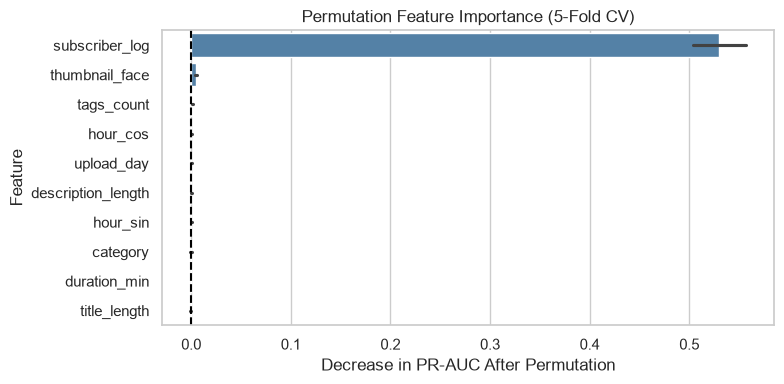

In [72]:
plt.figure(figsize=(8, 4))

sns.barplot(
    data=importance_df,
    x="Importance",
    y="Feature",
    order=importance_summary.index,
    color="steelblue",
    errorbar="sd"
)

plt.axvline(0, color="black", linestyle="--")

plt.title("Permutation Feature Importance (5-Fold CV)")
plt.xlabel("Decrease in PR-AUC After Permutation")
plt.ylabel("Feature")

plt.tight_layout()
plt.show()


#### Permutation Feature Importance

#### Objective
Evaluate the contribution of individual features to the predictive performance of the tuned Logistic Regression model.

#### Methodology
- Used permutation feature importance with stratified 5-fold cross-validation.
- Evaluated importance using Average Precision (PR-AUC).
- Repeated feature permutation 10 times per validation fold.
- Calculated the mean decrease in PR-AUC after shuffling each feature.

#### Results
| Feature | Mean Importance | Standard Deviation |
|---|---:|---:|
| subscriber_log | 0.5303 | 0.0269 |
| thumbnail_face | 0.0045 | 0.0011 |
| tags_count | 0.0010 | 0.0006 |
| hour_cos | 0.0001 | 0.0003 |
| upload_day | 0.0000 | 0.0003 |
| description_length | 0.0000 | 0.0004 |
| hour_sin | -0.0000 | 0.0006 |
| category | -0.0000 | 0.0007 |
| duration_min | -0.0002 | 0.0004 |
| title_length | -0.0005 | 0.0005 |

#### Key Findings
**1. Subscriber Count Dominates Predictive Performance**
Log-transformed subscriber count has the highest permutation importance (0.5303), substantially exceeding all other features.
This indicates that the model relies heavily on subscriber count when predicting video virality.
The finding is consistent with the earlier Mann–Whitney U test and Logistic Regression coefficient analysis.

**2. Thumbnail Face Presence Provides Limited Additional Information**
Thumbnail face presence has a small positive permutation importance of 0.0045.
Although it is statistically associated with virality, its additional contribution to predictive performance is relatively small.

**3. Content Category Has Negligible Conditional Predictive Importance**
Despite demonstrating a moderate association with virality during hypothesis testing (Cramér's V = 0.3060), content category has approximately zero permutation importance.
This suggests that category provides little additional predictive information once the model accounts for other features.
One possible explanation is overlapping information between content category and subscriber count.

**4. Video Duration and Upload Timing Have Minimal Importance**
Video duration and upload timing have permutation importance values close to zero.
This suggests that these variables contribute little additional predictive information to the fitted model.

### Conclusion
Subscriber count is the dominant predictor of YouTube virality in the current Logistic Regression model.
Other features, including thumbnail face presence, content category, and video duration, provide substantially smaller additional contributions.

However, permutation importance can be affected by correlated features, and the results do not establish causal relationships.

In [73]:
#feature albation 
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import cross_validate, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
import pandas as pd

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Use the same tuned classifier for every experiment
tuned_classifier = clone(
    best_pipeline.named_steps["classifier"]
)

# Define feature groups
feature_groups = {
    "Subscriber Only": ["subscriber_log"],

    "Without Subscriber": [
        col for col in X_train.columns
        if col != "subscriber_log"
    ],

    "Full Model": list(X_train.columns)
}

ablation_results = []

for name, selected_features in feature_groups.items():

    # Retain only preprocessing steps relevant
    # to the selected features
    transformers = []

    for transformer_name, transformer, columns in preprocessor.transformers:
        selected = [
            col for col in columns
            if col in selected_features
        ]

        if selected:
            transformers.append(
                (transformer_name, clone(transformer)
                 if transformer != "passthrough"
                 else "passthrough", selected)
            )

    subset_preprocessor = ColumnTransformer(
        transformers=transformers
    )

    pipeline = Pipeline([
        ("preprocessor", subset_preprocessor),
        ("classifier", clone(tuned_classifier))
    ])

    scores = cross_validate(
        pipeline,
        X_train[selected_features],
        y_train,
        cv=cv,
        scoring={
            "roc_auc": "roc_auc",
            "pr_auc": "average_precision",
            "f1": "f1"
        },
        n_jobs=-1
    )

    ablation_results.append({
        "Model": name,
        "ROC-AUC": scores["test_roc_auc"].mean(),
        "PR-AUC": scores["test_pr_auc"].mean(),
        "F1": scores["test_f1"].mean()
    })

ablation_df = pd.DataFrame(ablation_results)

display(ablation_df.round(4))

,Model,ROC-AUC,PR-AUC,F1
0,Subscriber Only,0.9062,0.7370,0.6426
1,Without Subscriber,0.6834,0.3935,0.4098
2,Full Model,0.9065,0.7392,0.6452



#### Feature Ablation Analysis

Three Logistic Regression models were evaluated using stratified 5-fold cross-validation:
1. Subscriber Only: Uses log-transformed subscriber count.
2. Without Subscriber: Uses all engineered features except subscriber count.
3. Full Model: Uses all 10 engineered features.
The same tuned classifier hyperparameters were used across all three models.

#### Key Findings

**1. Subscriber Count Accounts for Most Predictive Performance**
The subscriber-only model achieved a PR-AUC of 0.7370, compared to 0.7392 for the full model.
Adding nine additional features improved PR-AUC by only 0.0022, indicating that these features provide limited incremental predictive value.

**2. Removing Subscriber Count Substantially Reduces Performance**
Excluding subscriber count reduced PR-AUC from 0.7392 to 0.3935.
This demonstrates that subscriber count is a critical predictor in the current model.

**3. Statistical Significance Does Not Guarantee Predictive Importance**
Although content category and thumbnail face presence demonstrated statistically significant associations with virality, their additional predictive contributions were small.
This highlights the distinction between univariate statistical relationships and multivariate predictive performance.

### Conclusion
Subscriber count is the dominant predictor of video virality in this synthetic dataset. A model using subscriber count alone achieves nearly identical predictive performance to the full Logistic Regression model.


In [74]:
import shap
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

model = best_pipeline.named_steps["classifier"]
preprocessor = best_pipeline.named_steps["preprocessor"]

X_train_transformed = preprocessor.transform(X_train)

feature_names = preprocessor.get_feature_names_out()

if hasattr(X_train_transformed, "toarray"):
    X_train_transformed = X_train_transformed.toarray()

X_train_shap = pd.DataFrame(
    X_train_transformed,
    columns=feature_names
)

In [75]:
explainer = shap.LinearExplainer(
    model,
    X_train_shap
)

shap_values = explainer(X_train_shap)

print("SHAP values shape:", shap_values.values.shape)

Background dataset has 9600 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=9600 when initializing the masker.


SHAP values shape: (9600, 30)


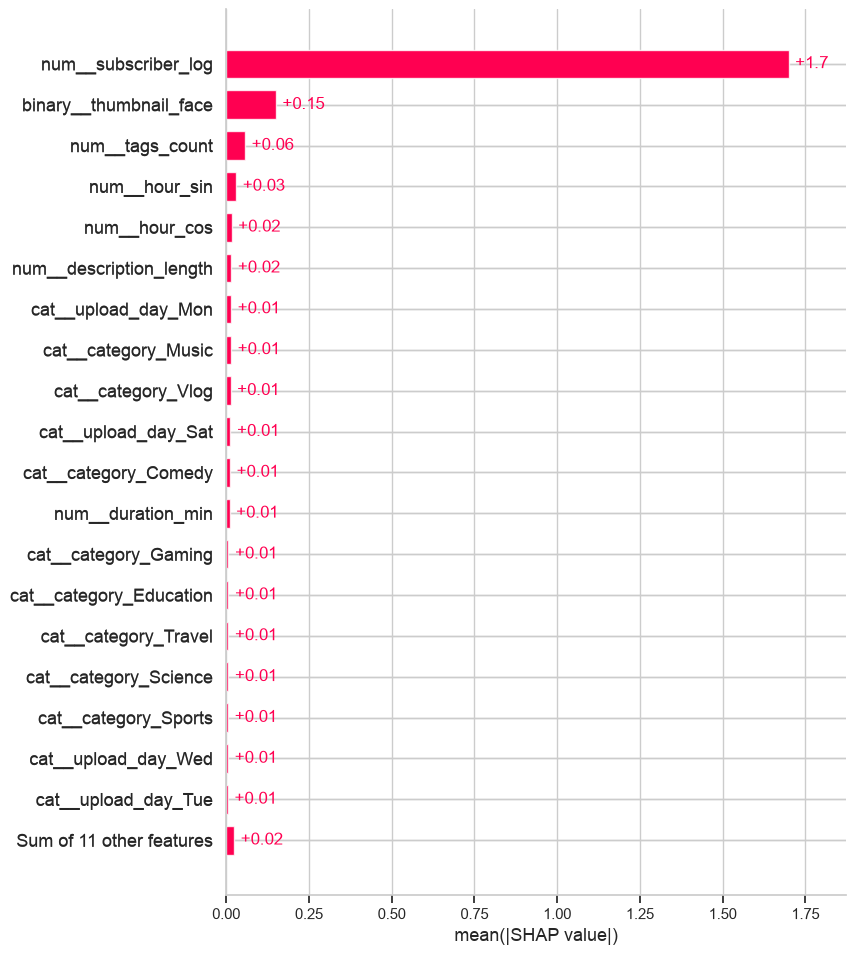

In [77]:
shap.plots.bar(
    shap_values,
    max_display=20
)

In [78]:
#error analysis 
error_df = X_test.copy()

error_df["actual"] = np.asarray(y_test)
error_df["predicted"] = y_test_pred
error_df["probability"] = y_test_prob

error_df["error_type"] = np.select(
    [
        (error_df["actual"] == 1) & (error_df["predicted"] == 0),
        (error_df["actual"] == 0) & (error_df["predicted"] == 1),
        (error_df["actual"] == 1) & (error_df["predicted"] == 1)
    ],
    [
        "False Negative",
        "False Positive",
        "True Positive"
    ],
    default="True Negative"
)

print(error_df["error_type"].value_counts())

error_type
True Negative     1731
True Positive      326
False Positive     189
False Negative     154
Name: count, dtype: int64


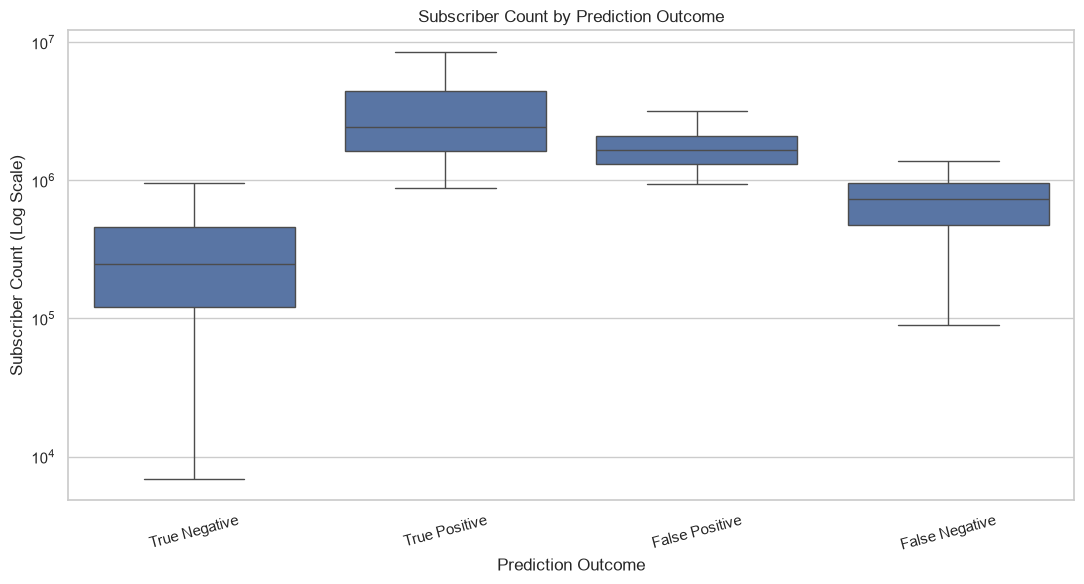

In [79]:
error_df["subscriber_count"] = np.expm1(
    error_df["subscriber_log"]
)

plt.figure(figsize=(11, 6))

sns.boxplot(
    data=error_df,
    x="error_type",
    y="subscriber_count",
    showfliers=False
)

plt.yscale("log")
plt.title("Subscriber Count by Prediction Outcome")
plt.xlabel("Prediction Outcome")
plt.ylabel("Subscriber Count (Log Scale)")
plt.xticks(rotation=15)

plt.tight_layout()
plt.show()

In [80]:
display(
    error_df.groupby("error_type")["subscriber_count"]
    .agg(["count", "median", "mean"])
    .round(0)
)

,count,median,mean
error_type,,,
False Negative,154,734697.0,724893.0
False Positive,189,1651692.0,1902611.0
True Negative,1731,249019.0,327071.0
True Positive,326,2455289.0,3978450.0


In [81]:
category_errors = (
    error_df.groupby("category")
    .agg(
        total=("actual", "size"),
        errors=("error_type", lambda x: x.isin(
            ["False Positive", "False Negative"]
        ).sum())
    )
)

category_errors["error_rate"] = (
    category_errors["errors"] /
    category_errors["total"]
)

display(
    category_errors.sort_values(
        "error_rate",
        ascending=False
    )
)

,total,errors,error_rate
category,,,
Music,142,33,0.232394
Comedy,156,33,0.211538
Beauty,188,37,0.196809
News,149,24,0.161074
Cooking,150,24,0.160000
Finance,163,26,0.159509
Sports,150,23,0.153333
Tech,162,24,0.148148
Education,171,25,0.146199


In [82]:
category_fn = (
    error_df.groupby("category")
    .apply(
        lambda g: pd.Series({
            "Actual_Viral": (g["actual"] == 1).sum(),
            "False_Negatives": (
                (g["actual"] == 1) &
                (g["predicted"] == 0)
            ).sum()
        }),
        include_groups=False
    )
)

category_fn["FN_Rate"] = (
    category_fn["False_Negatives"] /
    category_fn["Actual_Viral"].replace(0, np.nan)
)

display(
    category_fn.sort_values(
        "FN_Rate",
        ascending=False
    ).round(4)
)

,Actual_Viral,False_Negatives,FN_Rate
category,,,
Vlog,14,9,0.6429
Fitness,15,9,0.6000
Cooking,26,13,0.5000
Education,25,12,0.4800
Finance,33,15,0.4545
News,27,12,0.4444
Tech,30,13,0.4333
DIY,27,11,0.4074
Travel,18,7,0.3889



#### Error Analysis

#### Methodology
- Analysed predictions on the held-out test set.
- Compared subscriber counts across prediction outcomes.
- Calculated classification error rates by content category.
- Examined potential limitations arising from the model's reliance on subscriber count.

#### Key Findings

**1. Viral Videos From Relatively Smaller Channels Are More Likely to Be Missed**
False negatives have a median subscriber count of 734,697, compared with 2,455,289 for true positives.
This suggests that the model is more successful at detecting viral videos from larger channels.

**2. Large Channels Can Produce False Positives**
False positives have a median subscriber count of 1,651,692, substantially higher than the 249,019 median for true negatives.
This suggests that the model may overestimate the likelihood of virality for some videos from larger channels.

**3. Error Rates Differ Across Content Categories**
Music (23.24%), Comedy (21.15%), and Beauty (19.68%) have the highest observed classification error rates.
Science (5.48%), Vlog (7.30%), and Travel (8.13%) have the lowest.
However, these differences may partly reflect variations in viral prevalence across categories.

#### Conclusion
The error analysis reveals that the model relies heavily on subscriber count when predicting virality.
As a result, it tends to miss viral videos from relatively smaller channels and incorrectly classify some non-viral videos from larger channels as viral.
This limitation is consistent with the earlier feature ablation and SHAP analyses.
Although the model achieves strong overall discrimination, its predictions may be less reliable for videos whose performance differs substantially from expectations based on channel size.


### 6.YouTube View Count Regression

In [83]:
features = [
    "category",
    "duration_sec",
    "title_length",
    "thumbnail_face",
    "upload_hour",
    "upload_day",
    "tags_count",
    "description_length",
    "subscriber_count"
]

X = df[features].copy()
y = df["views"].copy()

print("Features:", X.shape)
print("Target:", y.shape)

Features: (12000, 9)
Target: (12000,)


In [84]:
view_bins = pd.qcut(
    y,
    q=10,
    labels=False,
    duplicates="drop"
)

X_train_reg, X_test_reg, y_train_reg, y_test_reg = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=view_bins
)

print("Training:", X_train_reg.shape)
print("Testing:", X_test_reg.shape)

Training: (9600, 9)
Testing: (2400, 9)


In [85]:
def engineer_features(X):
    X = X.copy()

    X["subscriber_log"] = np.log1p(
        X["subscriber_count"]
    )

    X["duration_min"] = (
        X["duration_sec"] / 60
    )

    X["hour_sin"] = np.sin(
        2 * np.pi * X["upload_hour"] / 24
    )

    X["hour_cos"] = np.cos(
        2 * np.pi * X["upload_hour"] / 24
    )

    X = X.drop(
        columns=[
            "subscriber_count",
            "duration_sec",
            "upload_hour"
        ]
    )

    return X

In [86]:
categorical_features = [
    "category",
    "upload_day"
]

numerical_features = [
    "title_length",
    "tags_count",
    "description_length",
    "subscriber_log",
    "duration_min",
    "hour_sin",
    "hour_cos"
]

binary_features = [
    "thumbnail_face"
]

numeric_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor_reg = ColumnTransformer([
    ("num", numeric_transformer, numerical_features),
    ("cat", categorical_transformer, categorical_features),
    ("binary", "passthrough", binary_features)
])

In [87]:
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor

regression_models = {
    "Dummy": DummyRegressor(
        strategy="median"
    ),

    "Linear Regression": LinearRegression(),

    "Random Forest": RandomForestRegressor(
        n_estimators=200,
        random_state=42,
        n_jobs=1
    ),

    "XGBoost": XGBRegressor(
        n_estimators=200,
        max_depth=4,
        learning_rate=0.05,
        objective="reg:squarederror",
        random_state=42,
        n_jobs=1
    )
}

In [88]:
from sklearn.compose import TransformedTargetRegressor
regression_pipelines = {}

for name, model in regression_models.items():

    pipeline = Pipeline([
        ("feature_engineering", FunctionTransformer(
            engineer_features,
            validate=False
        )),
        ("preprocessor", clone(preprocessor_reg)),
        ("regressor", clone(model))
    ])

    regression_pipelines[name] = TransformedTargetRegressor(
        regressor=pipeline,
        func=np.log1p,
        inverse_func=np.expm1
    )

In [89]:
from sklearn.model_selection import (
    train_test_split,
    KFold,
    cross_validate
)

In [90]:
from sklearn.metrics import make_scorer

def rmsle(y_true, y_pred):
    y_pred = np.maximum(y_pred, 0)

    return np.sqrt(
        np.mean(
            (
                np.log1p(y_true)
                - np.log1p(y_pred)
            ) ** 2
        )
    )

cv_reg = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

scoring_reg = {
    "MAE": "neg_mean_absolute_error",
    "RMSE": "neg_root_mean_squared_error",
    "R2": "r2",
    "RMSLE": make_scorer(
        rmsle,
        greater_is_better=False
    )
}

regression_results = []

for name, pipeline in regression_pipelines.items():

    scores = cross_validate(
        pipeline,
        X_train_reg,
        y_train_reg,
        cv=cv_reg,
        scoring=scoring_reg,
        n_jobs=-1
    )

    regression_results.append({
        "Model": name,
        "MAE": -scores["test_MAE"].mean(),
        "RMSE": -scores["test_RMSE"].mean(),
        "R2": scores["test_R2"].mean(),
        "RMSLE": -scores["test_RMSLE"].mean()
    })

regression_results_df = pd.DataFrame(
    regression_results
)

display(
    regression_results_df.sort_values(
        "RMSLE"
    ).round(4)
)

,Model,MAE,RMSE,R2,RMSLE
1,Linear Regression,512564.4227,2.671184e+06,0.3673,0.9516
3,XGBoost,522455.0500,2.815997e+06,0.3167,0.9605
2,Random Forest,530066.5089,2.732309e+06,0.3359,0.9798
0,Dummy,701097.2450,3.387997e+06,-0.0446,1.6407


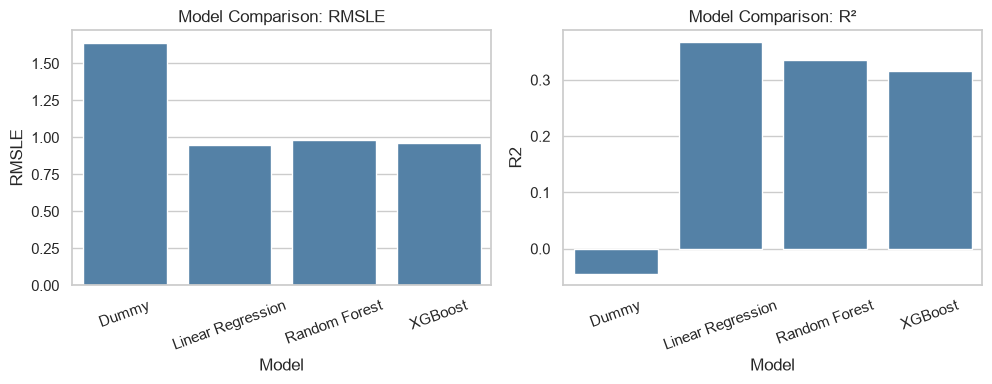

In [91]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

sns.barplot(
    data=regression_results_df,
    x="Model",
    y="RMSLE",
    ax=axes[0],
    color="steelblue"
)

axes[0].set_title("Model Comparison: RMSLE")
axes[0].tick_params(axis="x", rotation=20)

sns.barplot(
    data=regression_results_df,
    x="Model",
    y="R2",
    ax=axes[1],
    color="steelblue"
)

axes[1].set_title("Model Comparison: R²")
axes[1].tick_params(axis="x", rotation=20)

plt.tight_layout()
plt.show()


#### Regression Model Comparison

#### Objective

Compare regression models for predicting YouTube video views using pre-upload metadata.

#### Methodology

- Target variable: `views`
- Applied log transformation to the target variable.
- Used stratified train-test splitting based on view-count quantiles.
- Evaluated models using 5-fold cross-validation.
- Compared MAE, RMSE, R², and RMSLE.

#### Results

| Model | MAE | RMSE | R² | RMSLE |
|---|---:|---:|---:|---:|
| Linear Regression | 512564.42 | 2671184 | 0.3673 | 0.9516 |
| XGBoost | 522455.05 | 2815997 | 0.3167 | 0.9605 |
| Random Forest | 530066.51 | 2732309 | 0.3359 | 0.9798 |
| Dummy | 701097.25 | 3387997 | -0.0446 | 1.6407 |

#### Key Findings

**1. Linear Regression Achieved the Best Performance**
Linear Regression achieved the lowest MAE (512,564), RMSE (2.67 million), and RMSLE (0.9516), as well as the highest R² (0.3673).
This indicates that Linear Regression currently provides the strongest predictive performance among the evaluated models.

**2. Complex Models Did Not Outperform Linear Regression**
XGBoost and Random Forest performed slightly worse than Linear Regression.
This suggests that more complex nonlinear models do not necessarily provide better predictive performance for this dataset.
However, hyperparameter tuning may improve their results.

**3. Large Prediction Errors Remain**
The RMSE is substantially higher than the MAE, suggesting that some videos have very large prediction errors.
This may be related to the highly right-skewed distribution of video views.

**4. Regression Performance Is Limited**
Although Linear Regression outperformed the baseline, its R² of 0.3673 indicates that a substantial proportion of variation in view counts remains unexplained.

#### Conclusion
Linear Regression is currently the best-performing model for predicting YouTube video views.
However, prediction errors remain substantial, particularly on the original view-count scale.
Further analysis should focus on hyperparameter tuning, residual analysis, and evaluating whether prediction errors are concentrated among high-view videos.


In [92]:
#hyperparameter tuning 
from sklearn.linear_model import Ridge
from sklearn.model_selection import GridSearchCV
from sklearn.compose import TransformedTargetRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer
from sklearn.base import clone
import numpy as np

ridge_pipeline = Pipeline([
    ("feature_engineering", FunctionTransformer(
        engineer_features,
        validate=False
    )),
    ("preprocessor", clone(preprocessor_reg)),
    ("regressor", Ridge())
])

ridge_model = TransformedTargetRegressor(
    regressor=ridge_pipeline,
    func=np.log1p,
    inverse_func=np.expm1
)

param_grid = {
    "regressor__regressor__alpha": [
        0.01, 0.1, 1, 10, 100, 1000
    ]
}

ridge_search = GridSearchCV(
    estimator=ridge_model,
    param_grid=param_grid,
    scoring=make_scorer(
        rmsle,
        greater_is_better=False
    ),
    cv=cv_reg,
    n_jobs=-1,
    refit=True
)

ridge_search.fit(X_train_reg, y_train_reg)

print("Best parameters:", ridge_search.best_params_)
print("Best CV RMSLE:", -ridge_search.best_score_)

Best parameters: {'regressor__regressor__alpha': 100}
Best CV RMSLE: 0.9513783796777266


In [93]:
ridge_comparison = pd.DataFrame({
    "Model": ["Linear Regression", "Tuned Ridge"],
    "CV RMSLE": [
        0.9516,
        -ridge_search.best_score_
    ]
})

display(ridge_comparison.round(4))

,Model,CV RMSLE
0,Linear Regression,0.9516
1,Tuned Ridge,0.9514



### Regression Hyperparameter Tuning

Investigate whether Ridge Regression improves view-count prediction performance compared with ordinary Linear Regression.

#### Methodology

- Used Ridge Regression with L2 regularisation.
- Applied GridSearchCV with 5-fold cross-validation.
- Tested alpha values of 0.01, 0.1, 1, 10, 100, and 1000.
- Selected the model minimising RMSLE.
- Performed tuning using training data only.

#### Interpretation
Ridge Regression achieved a marginal improvement in RMSLE compared with ordinary Linear Regression.
The improvement of approximately 0.0002 suggests that L2 regularisation provides limited additional benefit for this dataset.

#### Conclusion
Tuned Ridge Regression was selected for final evaluation.
However, the difference in cross-validation performance is extremely small and does not establish that Ridge Regression generalises better than ordinary Linear Regression.

In [94]:
best_regression_model = ridge_search.best_estimator_

# Predict views on the test set
y_test_pred_reg = best_regression_model.predict(X_test_reg)

# Ensure predictions are non-negative
y_test_pred_reg = np.maximum(y_test_pred_reg, 0)

print("Number of predictions:", len(y_test_pred_reg))

print("\nFirst 10 predictions:")
print(y_test_pred_reg[:10])

Number of predictions: 2400

First 10 predictions:
[ 38372.00865908 277448.4566572  314073.78911751 222439.17784558
 808591.86251658  25603.04353694 280255.30009309  74429.46606341
 305669.8677027  817898.12309729]


In [95]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

test_mae = mean_absolute_error(
    y_test_reg,
    y_test_pred_reg
)

test_rmse = np.sqrt(
    mean_squared_error(
        y_test_reg,
        y_test_pred_reg
    )
)

test_r2 = r2_score(
    y_test_reg,
    y_test_pred_reg
)

test_rmsle = rmsle(
    y_test_reg,
    y_test_pred_reg
)

final_reg_results = pd.DataFrame({
    "Metric": ["MAE", "RMSE", "R²", "RMSLE"],
    "Score": [
        test_mae,
        test_rmse,
        test_r2,
        test_rmsle
    ]
})

display(final_reg_results.round(4))

,Metric,Score
0,MAE,5.024950e+05
1,RMSE,2.247413e+06
2,R²,2.735000e-01
3,RMSLE,9.716000e-01


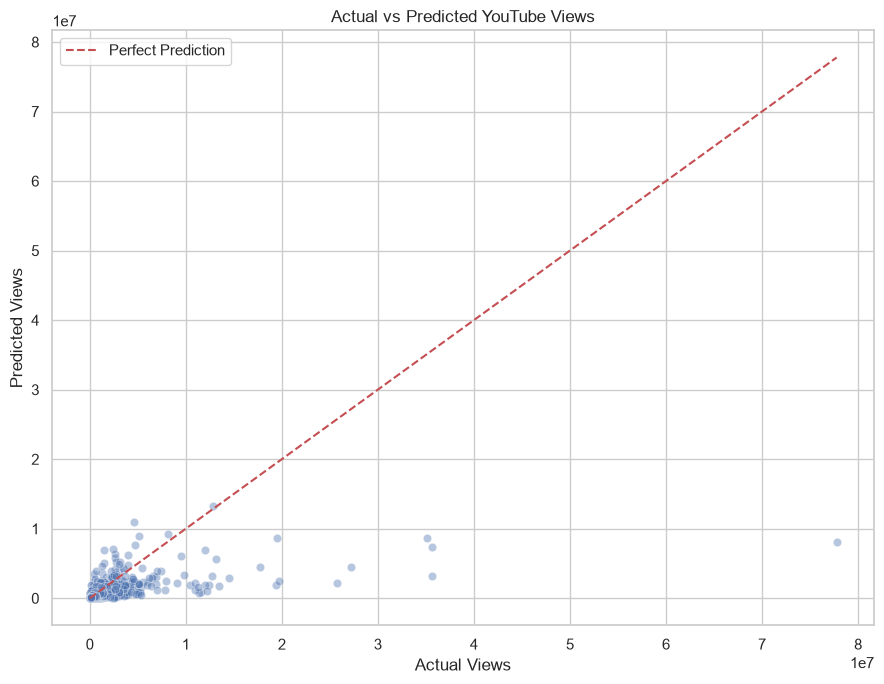

In [96]:
plt.figure(figsize=(9, 7))

sns.scatterplot(
    x=y_test_reg,
    y=y_test_pred_reg,
    alpha=0.4
)

max_views = max(
    y_test_reg.max(),
    y_test_pred_reg.max()
)

plt.plot(
    [0, max_views],
    [0, max_views],
    "r--",
    label="Perfect Prediction"
)

plt.xlabel("Actual Views")
plt.ylabel("Predicted Views")
plt.title("Actual vs Predicted YouTube Views")
plt.legend()

plt.tight_layout()
plt.show()

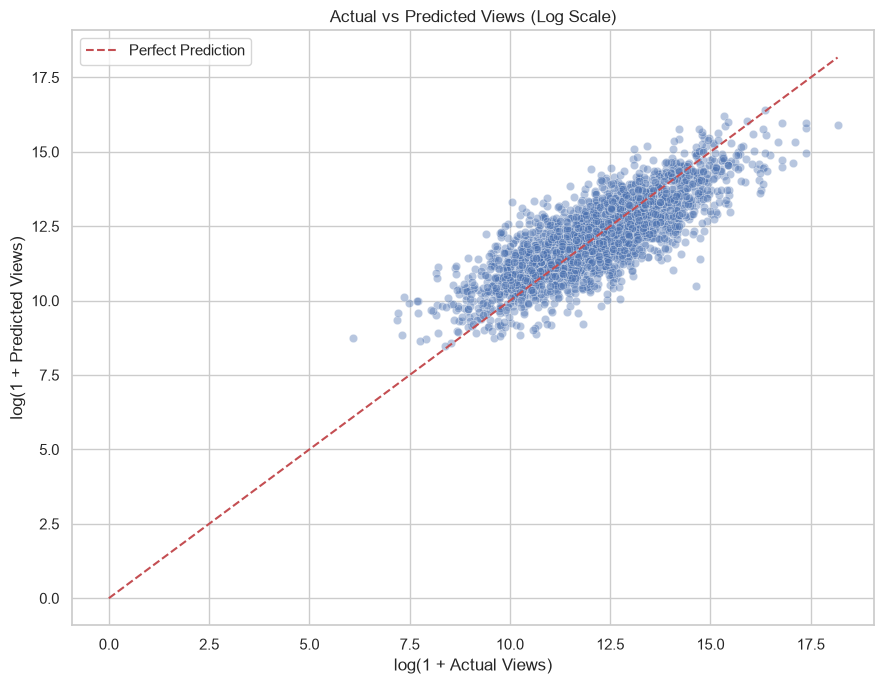

In [97]:
plt.figure(figsize=(9, 7))

sns.scatterplot(
    x=np.log1p(y_test_reg),
    y=np.log1p(y_test_pred_reg),
    alpha=0.4
)

max_log = max(
    np.log1p(y_test_reg).max(),
    np.log1p(y_test_pred_reg).max()
)

plt.plot(
    [0, max_log],
    [0, max_log],
    "r--",
    label="Perfect Prediction"
)

plt.xlabel("log(1 + Actual Views)")
plt.ylabel("log(1 + Predicted Views)")
plt.title("Actual vs Predicted Views (Log Scale)")
plt.legend()

plt.tight_layout()
plt.show()

In [98]:
residual_df = pd.DataFrame({
    "actual_views": np.asarray(y_test_reg),
    "predicted_views": y_test_pred_reg
})

residual_df["residual"] = (
    residual_df["actual_views"]
    - residual_df["predicted_views"]
)

residual_df["log_residual"] = (
    np.log1p(residual_df["actual_views"])
    - np.log1p(residual_df["predicted_views"])
)

display(residual_df.head())

,actual_views,predicted_views,residual,log_residual
0,42219,38372.008659,3846.991341,0.095540
1,190501,277448.456657,-86947.456657,-0.375976
2,332108,314073.789118,18034.210882,0.055832
3,563983,222439.177846,341543.822154,0.930368
4,412234,808591.862517,-396357.862517,-0.673702


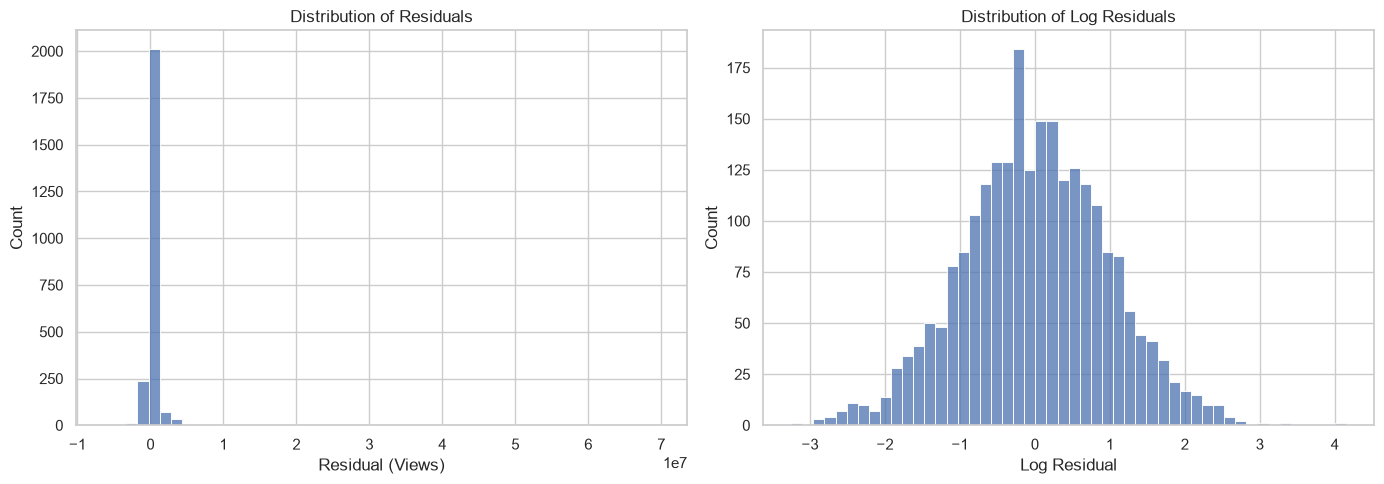

In [99]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(
    residual_df["residual"],
    bins=50,
    ax=axes[0]
)

axes[0].set_title("Distribution of Residuals")
axes[0].set_xlabel("Residual (Views)")

sns.histplot(
    residual_df["log_residual"],
    bins=50,
    ax=axes[1]
)

axes[1].set_title("Distribution of Log Residuals")
axes[1].set_xlabel("Log Residual")

plt.tight_layout()
plt.show()

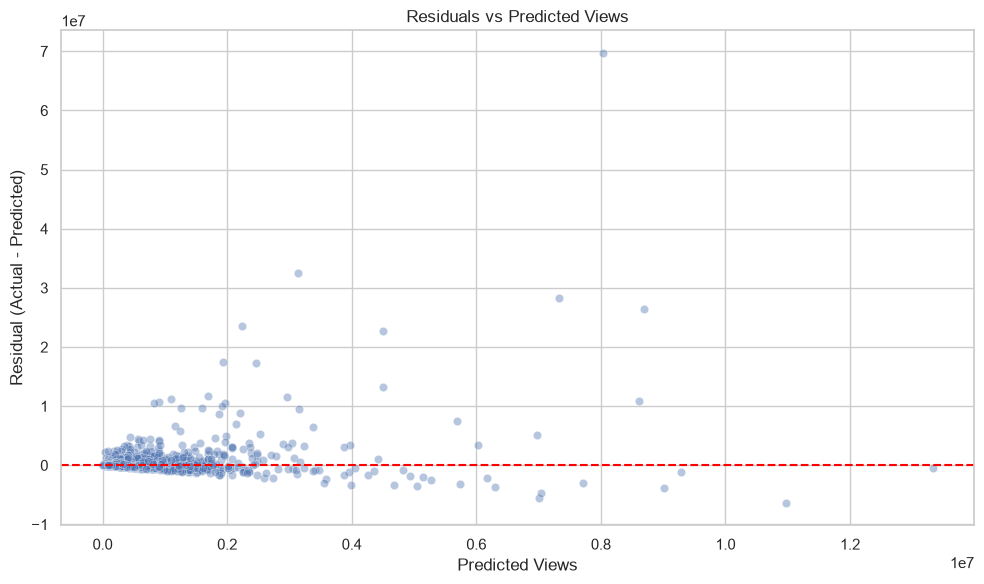

In [100]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=residual_df,
    x="predicted_views",
    y="residual",
    alpha=0.4
)

plt.axhline(
    0,
    color="red",
    linestyle="--"
)

plt.title("Residuals vs Predicted Views")
plt.xlabel("Predicted Views")
plt.ylabel("Residual (Actual - Predicted)")

plt.tight_layout()
plt.show()

In [101]:
residual_df["view_tier"] = pd.qcut(
    residual_df["actual_views"],
    q=4,
    labels=[
        "Q1 - Lowest Views",
        "Q2 - Low Views",
        "Q3 - High Views",
        "Q4 - Highest Views"
    ],
    duplicates="drop"
)

residual_df["absolute_error"] = (
    residual_df["residual"].abs()
)

error_by_tier = (
    residual_df.groupby(
        "view_tier",
        observed=True
    )
    .agg(
        count=("actual_views", "size"),
        median_actual_views=("actual_views", "median"),
        MAE=("absolute_error", "mean"),
        median_residual=("residual", "median"),
        mean_log_residual=("log_residual", "mean")
    )
)

display(error_by_tier.round(2))

,count,median_actual_views,MAE,median_residual,mean_log_residual
view_tier,,,,,
Q1 - Lowest Views,600,28489.5,53167.82,-22426.15,-0.76
Q2 - Low Views,600,110819.0,93354.49,-20091.72,-0.13
Q3 - High Views,600,307479.5,225718.96,57325.90,0.20
Q4 - Highest Views,600,1271211.0,1637738.71,518843.56,0.70



#### Regression Residual Analysis
Evaluate prediction errors of the tuned Ridge Regression model and investigate whether performance differs across view-count ranges.

#### Methodology

- Generated predictions on the held-out test set.
- Compared actual and predicted views using scatterplots.
- Calculated residuals as actual views minus predicted views.
- Analysed prediction errors across four actual view-count quartiles.
- Examined both absolute errors and log-scale residuals.

#### Key Findings

**1. Prediction Errors Increase for High-View Videos**
The highest-view quartile has an MAE of approximately 1.64 million views, compared with approximately 53,168 views for the lowest quartile.
This indicates that the model makes substantially larger absolute prediction errors for highly viewed videos.

**2. Low-View Videos Tend to Be Overpredicted**
The lowest two quartiles have negative median residuals, indicating that predicted views generally exceed actual views.

**3. High-View Videos Tend to Be Underpredicted**
The highest two quartiles have positive median residuals, indicating that actual views generally exceed predicted views.
The highest-view quartile has a median residual of approximately 518,844 views.

**4. Predictions Are Compressed Toward Typical Values**
The actual-versus-predicted scatterplot shows that the model tends to overestimate low-view videos and underestimate high-view videos.
This suggests that the model captures general view-count trends but struggles to predict extreme outcomes.

#### Possible Explanations
- Regression toward typical outcomes.
- Limited information available from pre-upload metadata.
- High variability in video performance.
- Effects of log-transforming the target variable.

#### Conclusion
The tuned Ridge Regression model captures the overall relationship between video characteristics and view counts but exhibits systematic prediction errors across view-count ranges.
It tends to overpredict less popular videos and underpredict highly popular videos.
These findings suggest that pre-upload metadata alone may be insufficient to accurately predict extreme video performance.
The results are based on synthetic data and should not be generalised directly to real YouTube behaviour.


In [102]:
# Extract the fitted pipeline
ridge_pipeline = best_regression_model.regressor_

# Extract Ridge model
ridge_estimator = ridge_pipeline.named_steps["regressor"]

# Extract preprocessor
ridge_preprocessor = ridge_pipeline.named_steps["preprocessor"]

# Get feature names
feature_names = ridge_preprocessor.get_feature_names_out()

# Create coefficient table
ridge_coef_df = pd.DataFrame({
    "Feature": feature_names,
    "Coefficient": ridge_estimator.coef_
})

ridge_coef_df["Abs_Coefficient"] = (
    ridge_coef_df["Coefficient"].abs()
)

display(
    ridge_coef_df.sort_values(
        "Abs_Coefficient",
        ascending=False
    ).head(15)
)

,Feature,Coefficient,Abs_Coefficient
3,num__subscriber_log,1.311584,1.311584
29,binary__thumbnail_face,0.216133,0.216133
8,cat__category_Comedy,0.079454,0.079454
1,num__tags_count,0.050339,0.050339
17,cat__category_Science,-0.047792,0.047792
14,cat__category_Gaming,0.045096,0.045096
12,cat__category_Finance,0.040992,0.040992
15,cat__category_Music,-0.039376,0.039376
24,cat__upload_day_Sat,-0.030859,0.030859
11,cat__category_Education,-0.028359,0.028359


In [103]:
from sklearn.inspection import permutation_importance
from sklearn.model_selection import KFold
from sklearn.base import clone
import pandas as pd

cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

importance_results = []

for fold, (train_idx, val_idx) in enumerate(
    cv.split(X_train_reg)
):
    X_fold_train = X_train_reg.iloc[train_idx]
    X_fold_val = X_train_reg.iloc[val_idx]

    y_fold_train = y_train_reg.iloc[train_idx]
    y_fold_val = y_train_reg.iloc[val_idx]

    fold_model = clone(best_regression_model)
    fold_model.fit(X_fold_train, y_fold_train)

    result = permutation_importance(
        fold_model,
        X_fold_val,
        y_fold_val,
        scoring=make_scorer(
            rmsle,
            greater_is_better=False
        ),
        n_repeats=10,
        random_state=42,
        n_jobs=-1
    )

    for feature, importance in zip(
        X_train_reg.columns,
        result.importances_mean
    ):
        importance_results.append({
            "Fold": fold + 1,
            "Feature": feature,
            "Importance": importance
        })

importance_df_reg = pd.DataFrame(importance_results)

importance_summary_reg = (
    importance_df_reg.groupby("Feature")["Importance"]
    .agg(["mean", "std"])
    .sort_values("mean", ascending=False)
)

display(importance_summary_reg.round(4))

,mean,std
Feature,,
subscriber_count,1.1375,0.0300
thumbnail_face,0.0125,0.0011
tags_count,0.0028,0.0006
title_length,0.0002,0.0002
upload_hour,0.0002,0.0001
duration_sec,0.0001,0.0001
description_length,-0.0000,0.0000
category,-0.0001,0.0004
upload_day,-0.0002,0.0004



#### Regression Feature Importance
Identify the features contributing most strongly to view-count prediction using Ridge Regression coefficients and permutation feature importance.

#### Methodology
- Extracted coefficients from the tuned Ridge Regression model.
- Analysed the direction and magnitude of feature coefficients.
- Calculated permutation importance using stratified 5-fold cross-validation.
- Used RMSLE as the evaluation metric for permutation importance.

#### Key Findings

**1. Subscriber Count Is the Dominant Predictor**
Log-transformed subscriber count has the largest Ridge Regression coefficient (1.3116).
A one-standard-deviation increase in log subscriber count is associated with approximately 3.71 times the predicted value of (views + 1), holding other predictors constant.
Permutation importance further confirms its dominance, with shuffling subscriber count increasing RMSLE by approximately 1.1375.

**2. Thumbnail Face Presence Has a Smaller Positive Contribution**
Thumbnail face presence has a coefficient of 0.2161, corresponding to approximately 24% higher predicted (views + 1), holding other features constant.
However, its permutation importance of 0.0125 indicates that its additional predictive contribution is relatively small.

**3. Other Video Characteristics Contribute Limited Additional Information**
Content category, video duration, upload timing, title length, and description length have permutation importance values close to zero.
This suggests that these features provide limited additional predictive information beyond subscriber count.

**4. Results Are Consistent With Classification Findings**
Both the classification and regression analyses identify subscriber count as the dominant predictor.
Thumbnail face presence provides a smaller positive contribution, while other features have relatively limited predictive importance.

#### Conclusion
Subscriber count is the primary predictor of video views in the synthetic dataset.
Although other video characteristics show some statistical associations with video performance, their additional contributions to predictive accuracy are small.
The consistency between classification and regression findings suggests that the available pre-upload metadata primarily predicts video success through existing channel popularity.
However, these results reflect relationships in a synthetic dataset and should not be interpreted as causal effects or generalised directly to real YouTube performance.